# Phase 2 · 14단원 — 나이브 베이즈

> "단어들끼리 아무 상관이 없다"는 거짓말을 하고도,
> 텍스트 분류에서는 더 정교한 모델들보다 정확합니다. 왜 그런지가 이 단원입니다.

- 원문: <https://aiengineeringfromscratch.com/lesson?path=phases/02-ml-fundamentals/14-naive-bayes>
- 예상 시간: 90분 · 선수 지식: Phase 1(확률), Phase 2 3단원(로지스틱), 8단원(TF-IDF), 10단원(편향-분산)

---

## 📌 출처 표시 규칙

> 📗 **원문** — 커리큘럼에 있는 내용입니다.

> ✨ **추가** — 원문에는 없고, 제가 넣은 비유·예시·실험입니다.

---

## 🎯 이 단원에서 배우는 것

> 📗 **원문** — "Learning Objectives"

1. **베이즈 정리**에서 출발해 나이브 베이즈를 **밑바닥부터** 만듭니다 (Multinomial·Gaussian).
2. 독립 가정이 왜 틀렸는데도 잘 되는지 측정으로 확인합니다.
3. **라플라스 스무딩**과 **로그 공간 계산**이 왜 필수인지 직접 깨뜨려 봅니다.
4. **세 변종**(Multinomial·Gaussian·Bernoulli)을 비교하고 언제 뭘 쓸지 정합니다.

### 🔑 이 단원의 주제 — 확률은 틀리는데 분류는 맞습니다

"틀린 모델이 이긴다"는 말은 바로 와닿지 않습니다. **뭐가 틀렸고 뭘 이겼는지**를 나눠 봐야 하거든요.

나이브 베이즈는 두 가지를 내놓습니다. 그 둘의 신뢰도가 다릅니다.

| 모델이 내놓는 것 | 믿을 수 있나 | 어디서 확인하나 |
| --- | --- | --- |
| "이 메일이 스팸일 확률은 **99.7%**" 라는 **숫자** | ❌ 못 믿습니다 | 10절 (90%를 "99% 확실"이라 하는데 7%는 틀립니다) |
| "스팸 점수가 정상 점수보다 **크다**" 는 **비교** | ✅ 맞습니다 | 5·8·11절 (정확도 88%) |

그런데 **분류는 비교만 하면 됩니다.** 둘 중 어느 쪽 점수가 큰지만 알면 되지,
그 값이 0.997인지 0.6인지는 쓸 일이 없거든요.
그래서 **확률 계산을 망가뜨리는 가정을 해도 분류는 멀쩡합니다.** 이게 이 단원의 전부입니다.

> 🧸 항상 "완전 최고!" 아니면 "완전 최악!" 이라고만 말하는 친구가 있다고 해 보세요.
> 점수는 과장됐지만 **순위는 정확합니다.** 어디서 밥 먹을지 고르는 데는 아무 문제가 없죠.
> (10절에서 이 비유를 다시 씁니다)

그럼 그 '틀린 가정'이 뭘까요? **"단어들이 서로 아무 상관이 없다"** 입니다.
'machine' 과 'learning' 은 같이 나오는데도 무관하다고 칩니다. 명백한 거짓말이죠.
**1절에서 왜 그런 거짓말을 하는지, 7절에서 실제로 얼마나 틀렸는지 재 봅니다.**

> 📗 원문: "**the best model is not the most correct one, it is the one with the best
> bias-variance tradeoff for your data.**"
>
> (최고의 모델은 가장 옳은 모델이 아니라, 내 데이터에 편향-분산 균형이 가장 좋은 모델입니다.)

10단원이 그 균형을 재는 법이었고, 이 단원은 그 극단적인 사례입니다.

### 📗 왜 텍스트에서 다른 모델들이 막히나

| 모델 | 1만 차원 텍스트에서 | 이 노트북 |
| --- | --- | --- |
| **로지스틱 회귀** | 가중치 1만 개를 안정적으로 추정할 **데이터가 부족** | 8절에서 측정 |
| **결정 트리** | 한 번에 단어 하나로 쪼개서 **심하게 과적합** | 4단원 5절 |
| **KNN** | 1만 차원에서는 **모든 점이 똑같이 멉니다** | 6단원 7절 (차원의 저주) |
| **나이브 베이즈** | **한 번 훑으며 세기만** 하면 끝. 수백만 특징도 됨 | 이 단원 |

---

## 📖 목차

| # | 내용 | 출처 |
| --- | --- | --- |
| 0 | 베이즈 정리 복습 | 📗 원문 |
| 1 | 🔑 나이브 독립 가정 | 📗 원문 + ✨ 계산 |
| 2 | ✍️ 손으로 따라가는 계산 | 📗 원문 그대로 |
| 3 | 🔑 라플라스 스무딩 — 0의 저주 | 📗 원문 + ✨ 깨뜨려 보기 |
| 4 | 🔑 로그 공간 — 언더플로 막기 | 📗 원문 + ✨ 깨뜨려 보기 |
| 5 | 🔨 MultinomialNB 밑바닥부터 | 📗 원문 |
| 6 | 🔨 GaussianNB 밑바닥부터 | 📗 원문 |
| 7 | ⚠️ 독립 가정이 얼마나 틀렸나 | 📗 원문 + ✨ 측정 |
| 8 | 🔑 NB vs 로지스틱 회귀 | 📗 원문 + ✨ 실측 |
| 9 | 세 변종 비교 (+ ⚠️ 원문 검증) | 📗 원문 + ✨ 실험 |
| 10 | 확률 보정 — NB의 약점 | 📗 원문 + ✨ 측정 |
| 11 | 속도 — NB의 숨은 무기 | 📗 원문 + ✨ 측정 |
| 12 | NB가 실패하는 경우 | 📗 원문 + ✨ XOR 실험 |
| 13 | 🎒 Ship It — 변종 선택 가이드 | 📗 원문 `outputs/` |
| 14 | 📝 자가 점검 퀴즈 (5문항) | 📗 원문 `quiz.json` |
| 15 | 용어 사전 · 연습문제 | 📗 원문 |

---

## 🗺️ 이 단원은 이렇게 이어집니다

> ✨ **추가** — 절이 왜 이 순서인지 먼저 짚고 갑니다. 하나가 다음 하나를 불러옵니다.

**0절**에서 베이즈 정리를 복습합니다. 우리가 원하는 건 $P(\text{클래스} \mid \text{단어들})$ 인데,
그걸 직접 세는 건 불가능합니다. 베이즈 정리로 **뒤집어서** $P(\text{단어들} \mid \text{클래스})$ 로 바꿉니다.

그런데 그것도 여전히 불가능합니다. 단어 1만 개의 **공동 분포**를 추정해야 하니까요.

- **1절**: 그래서 거짓말을 합니다. "모든 단어가 서로 독립이다." 그러면 곱셈으로 쪼개집니다.
  이 거짓말이 이 단원의 전부입니다.
- **2절 ✍️**: 원문의 숫자 예제를손으로 따라갑니다. 식을 코드로 옮기기 전에 감을 잡습니다.

그런데 손으로 해 보면 두 군데서 터집니다.

- **3절**: 훈련에 없던 단어가 나오면 확률이 **0**이 되고, 곱셈 전체가 0이 됩니다. **스무딩**이 필요합니다.
- **4절**: 작은 확률 수백 개를 곱하면 **언더플로**로 0이 됩니다. **로그 공간**이 필요합니다.
  그리고 로그로 바꾸면 **행렬 곱**이 되어 엄청 빨라집니다 (11절에서 측정).

두 문제를 해결했으니 이제 만들 수 있습니다.

- **5·6절 🔨**: **MultinomialNB**(단어 세기)와 **GaussianNB**(연속값)를 각각 만들고 sklearn과 대조합니다.

만들고 나면 **처음의 거짓말**로 돌아갑니다.

- **7절 ⚠️**: 독립 가정이 **실제로 얼마나 틀렸는지** 측정합니다 (실제 공존 확률 vs 가정).
- **8절**: 그런데도 로지스틱 회귀를 이깁니다. 데이터 크기를 바꿔 가며 언제까지 이기는지 봅니다.
- **9절**: 세 변종을 비교합니다. ⚠️ 여기서 원문 주장 하나가 재현되지 않습니다.

마지막으로 **약점**을 봅니다.

- **10절**: 확률이 극단으로 치우칩니다(0.99 아니면 0.01). 보정하는 법.
- **11절**: 대신엄청 빠릅니다. 측정해 봅니다.
- **12절**: **XOR 같은 상호작용**에는 완전히 실패합니다. 직접 보입니다.

### 한 줄로 꿰면

> **베이즈로 뒤집고(0) → 독립이라 거짓말하고(1) → 손으로 계산하고(2)
> → 0을 막고(3) → 언더플로를 막고(4) → 만들고(5·6)
> → 거짓말의 크기를 재고(7) → 그래도 이기는 걸 보고(8) → 변종을 고르고(9)
> → 약점(확률·상호작용)을 알고(10·12) → 속도라는 무기를 확인(11)**

---

## 🧭 길잡이 — 이 단원을 왜 배우나

### 지금 어디쯤 와 있나

1단원부터 13단원까지는 **"어떤 모델이 더 좋은가"** 를 배웠습니다.
선형이냐 트리냐, 규제를 얼마나 걸 것이냐 같은 이야기였죠.

14단원부터는 질문이 바뀝니다.
**"지금까지 당연하게 쓰던 기본값이 통하지 않는 상황"** 을 하나씩 보게 됩니다.
네 단원이 한 묶음이에요.

**14단원**은 텍스트입니다. 특징이 수만 개인데 샘플은 적죠. 여기서 "정교한 모델일수록 낫다"는
감각이 깨집니다. 세기만 하는 단순한 모델이 이기거든요.

**15단원**은 시간이 붙은 데이터입니다. 샘플이 서로 독립이 아니라서, 9단원에서 배운
k-겹 교차검증을 쓸 수가 없습니다.

**16단원과 17단원**은 찾는 대상이 아주 드문 경우입니다. 레이블이 없으면 16단원(이상 탐지),
있으면 17단원(불균형 데이터)이고, 둘 다 정확도와 기본 임곗값 0.5 를 버리는 데서 출발합니다.

그래서 이 네 단원은 한마디로 **기본값을 의심하는 연습**입니다.
절 제목에 ⚠️ 가 붙은 곳이 바로 그 기본값이 깨지는 지점이에요.
시간이 없으시면 거기부터 보셔도 됩니다.

> 🧭 **지금 보시는 14단원**은 텍스트를 다룹니다. 특징이 수만 개인데 샘플은 적죠. 여기서 "정교한 모델일수록 낫다"는 감각이 깨집니다. 세기만 하는 단순한 모델이 이기거든요.


### 이 단원이 끝나면 할 수 있는 것

텍스트 분류 과제를 받았을 때 **1분 안에 쓸 만한 기준선**을 세울 수 있게 됩니다.
그리고 그 기준선 덕분에 "정확도 88%" 라는 숫자가 좋은 건지 나쁜 건지 판단할 수 있게 되죠.
모델이 "확률 99%" 라고 말할 때 그 숫자를 믿어도 되는지도 알게 되고,
반대로 나이브 베이즈를 **쓰면 안 되는** 문제가 어떤 종류인지도 미리 알아보게 됩니다.

### 실험을 따라가는 순서

여기서부터는 각 절이 어떤 질문을 던지고, 출력의 **어느 숫자를 봐야 하고**,
그래서 무엇을 알게 되는지를 순서대로 적었습니다.
한 번 훑어 두시면 본문에서 숫자가 쏟아질 때 길을 잃지 않습니다.

**1절**은 "독립 가정을 안 하면 뭘 추정해야 하나"를 묻습니다.
표에서 `공동 분포의 경우 수` 열과 `독립 가정이면` 열을 비교해 보세요.
$2^{10000}$ 과 1만 개입니다. 여기서 알게 되는 건 이 거짓말이 **정확성의 문제가 아니라
실행 가능성의 문제**라는 겁니다. 거짓말을 안 하면 애초에 계산이 불가능하거든요.

**2절**은 그 식을 손으로 따라갑니다. 합계 `-3.108` 과 `-8.841` 두 숫자만 확인하면 됩니다.
원문의 −3.109 / −8.838 과 맞으면 식을 코드로 옮긴 게 맞는 거죠.

그런데 손으로 해 보면 두 군데서 계산이 **터집니다.** 그게 3절과 4절입니다.

**3절**에서는 α=0 행의 `log P(정상) = -inf` 를 보세요.
훈련에 없던 단어 **하나** 때문에 올바른 답이 탈락합니다. 그래서 스무딩은 선택이 아니라 필수입니다.

**4절**에서는 `직접 곱하기` 열이 `underflow` 로 바뀌는 지점을 보세요. 단어 194개입니다.
흔한 길이의 문서에서 이미 터지죠. 로그 공간도 필수입니다.

**5절과 6절**은 직접 만들어 보는 절입니다. `log가능도 최대 차이: 1.78e-15` 한 줄만
확인하면 됩니다. 10줄로 sklearn 을 재현했다는 뜻이에요.

**7절**이 이 단원의 핵심 증거입니다. `비율` 열에서 독립 가정이 **2.4배** 틀렸다고 나오는데,
같은 모델의 정확도는 **87.9%** 입니다. 이 두 숫자를 나란히 보세요.
가정이 틀린 정도와 성능이 따로 논다는 게 눈에 보입니다.

**8절**은 "데이터가 많아지면 로지스틱 회귀가 이기나"를 묻습니다. `NB 우위` 열만 따라가세요.
50개에서 +12.5%p, 2320개에서 +7.9%p 입니다. 격차는 줄지만 **역전이 안 옵니다.**
교과서의 "큰 데이터면 로지스틱"이라는 말에 조건이 붙는다는 뜻이죠.

**9절**에서는 `텍스트 (0/1 이진)` 행 하나만 보면 됩니다.
이진 데이터인데도 Multinomial 이 이깁니다. Bernoulli 를 꼭 써야 할 상황이 드물다는 뜻입니다.

**10절**은 앞에서 말한 "확률은 못 믿는다"를 숫자로 보여 줍니다.
`극단 확률 비율` **90.1%** 와 정확도 **93.0%** 를 나란히 보세요.
90%를 "99% 확실"이라고 말하는데 그중 7%는 틀립니다.

**11절**은 속도입니다. `학습(초)` 열을 보세요. 수십 밀리초입니다.
그래서 기준선으로 쓸 수 있고, 12단원의 하이퍼파라미터 탐색도 수천 번 돌릴 수 있습니다.

**12절**은 실패하는 경우입니다. XOR 표에서 NB 세 변종이 전부 50% 근처입니다.
특징이 몇 개 안 되고 **조합**이 중요한 문제면 트리 계열로 가야 합니다.

### 한 문장으로 꿰면

가정이 틀려도 **순위만 맞으면 분류는 됩니다.**
스무딩과 로그 공간 없이는 계산 자체가 안 되고,
나온 확률은 순위만 믿고 값은 믿지 마세요.

In [1]:
# ── 준비물 ──────────────────────────────────────────────────────
import math
import re
import time
from collections import Counter

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

np.set_printoptions(precision=4, suppress=True)

available = {f.name for f in fm.fontManager.ttflist}
for cand in ["Apple SD Gothic Neo", "AppleGothic", "NanumGothic",
             "NanumBarunGothicOTF", "Malgun Gothic", "Noto Sans CJK KR"]:
    if cand in available:
        matplotlib.rcParams["font.family"] = ["DejaVu Sans", cand]
        break
matplotlib.rcParams["axes.unicode_minus"] = False
matplotlib.rcParams["figure.dpi"] = 110

print("준비 끝!")

준비 끝!


## 0️⃣ 베이즈 정리 복습

> 📗 **원문** — "Bayes' Theorem (Quick Review)"

$$P(\text{클래스} \mid \text{특징}) = \frac{P(\text{특징} \mid \text{클래스}) \cdot P(\text{클래스})}{P(\text{특징})}$$

### 📗 각 항이 무엇인가

| 항 | 이름 | 뜻 | 세기 쉬운가 |
| --- | --- | --- | --- |
| $P(\text{클래스} \mid \text{특징})$ | **사후확률** | 이 단어들이 있을 때 스팸일 확률 | ❌ **우리가 원하는 것** |
| $P(\text{특징} \mid \text{클래스})$ | **가능도** | 스팸 메일에 이 단어들이 나올 확률 | ✅ **셀 수 있습니다** |
| $P(\text{클래스})$ | **사전확률** | 전체 메일 중 스팸 비율 | ✅ 아주 쉽습니다 |
| $P(\text{특징})$ | **증거** | 이 단어들이 나올 확률 | 🤷 **클래스마다 같아서 무시** |

### 🔑 왜 뒤집는 게 이득인가요?

"스팸이면서 이 단어 조합인 메일" 을 세려면 그 조합이 훈련 데이터에 있어야 합니다.
단어 조합은 사실상 무한하니 **대부분 0개**입니다.

**뒤집으면** "스팸 메일에 '무료'가 몇 번 나왔나"를 셉니다.이건 쉽습니다.

### 🧸 비유 — 병원에서 거꾸로 묻기

"기침하는 사람이 폐렴일 확률"은 재기 어렵습니다. 기침하는 사람을 다 모아 검사해야 하죠.

그런데 "폐렴 환자가 기침할 확률"은 쉽습니다. 폐렴 환자 차트를 보면 됩니다.

베이즈 정리는 쉬운 쪽에서 어려운 쪽으로 넘어가는 다리입니다.
단, **사전확률**(폐렴이 전체에서 얼마나 흔한가)을 곱해 줘야 합니다.
흔하지 않은 병이면 기침해도 폐렴일 확률은 낮으니까요.

In [2]:
# ✨ 추가 — 베이즈 정리를 '병원' 예시로 직접 계산합니다
P_폐렴 = 0.01                  # 전체 인구의 1%
P_기침_폐렴 = 0.90             # 폐렴 환자 중 90%가 기침
P_기침_정상 = 0.08             # 건강한 사람 중 8%도 기침

P_기침 = P_기침_폐렴 * P_폐렴 + P_기침_정상 * (1 - P_폐렴)
P_폐렴_기침 = P_기침_폐렴 * P_폐렴 / P_기침

print(f"사전확률 P(폐렴)        = {P_폐렴:.1%}")
print(f"가능도   P(기침|폐렴)    = {P_기침_폐렴:.1%}")
print(f"증거     P(기침)        = {P_기침:.2%}")
print(f"사후확률 P(폐렴|기침)    = {P_폐렴_기침:.1%}\n")
print(f"=> 기침하는 사람이 폐렴일 확률은 {P_폐렴_기침:.1%} 입니다.")
print(f"   '폐렴이면 90% 기침' 이라는 숫자와 전혀 다릅니다.")
print(f"   폐렴이 드물기({P_폐렴:.0%}) 때문입니다. 사전확률이 결과를 지배합니다.")

print(f"\n[사전확률을 바꾸면]")
print(f"{'P(폐렴)':>10}{'P(폐렴|기침)':>15}")
print("-" * 26)
for prior in [0.001, 0.01, 0.1, 0.5]:
    증거 = P_기침_폐렴 * prior + P_기침_정상 * (1 - prior)
    print(f"{prior:>10.1%}{P_기침_폐렴 * prior / 증거:>15.1%}")

print("\n=> 📗 원문의 'P(class) -- how common is spam in general?' 가 이 이야기입니다.")
print("   ⚠️ 그리고 14단원 Gotchas 에 나오는 '클래스 불균형' 문제의 뿌리이기도 합니다.")
print("      메일의 99%가 정상이면 사전확률이 너무 강해서 가능도를 압도합니다.")

사전확률 P(폐렴)        = 1.0%
가능도   P(기침|폐렴)    = 90.0%
증거     P(기침)        = 8.82%
사후확률 P(폐렴|기침)    = 10.2%

=> 기침하는 사람이 폐렴일 확률은 10.2% 입니다.
   '폐렴이면 90% 기침' 이라는 숫자와 전혀 다릅니다.
   폐렴이 드물기(1%) 때문입니다. 사전확률이 결과를 지배합니다.

[사전확률을 바꾸면]
     P(폐렴)       P(폐렴|기침)
--------------------------
      0.1%           1.1%
      1.0%          10.2%
     10.0%          55.6%
     50.0%          91.8%

=> 📗 원문의 'P(class) -- how common is spam in general?' 가 이 이야기입니다.
   ⚠️ 그리고 14단원 Gotchas 에 나오는 '클래스 불균형' 문제의 뿌리이기도 합니다.
      메일의 99%가 정상이면 사전확률이 너무 강해서 가능도를 압도합니다.


---

## 1️⃣ 🔑 나이브 독립 가정

> 📗 **원문** — "The Naive Independence Assumption"
>
> 🔗 **앞 절과 이어서** — 0절에서 베이즈 정리로 뒤집었습니다.
> 그런데 뒤집은 쪽도 여전히 불가능합니다.

### ⚠️ 왜 불가능한가

$P(w_1, w_2, \ldots, w_n \mid \text{클래스})$ 를 정확히 추정하려면
**모든 단어의 공동 분포**가 필요합니다.

> 📗 원문: "With a vocabulary of 10,000 words, you would need to estimate a distribution
> over $2^{10,000}$ possible combinations. **Impossible.**"

### 📗 그래서 거짓말을 합니다

$$P(w_1, w_2, \ldots, w_n \mid c) = P(w_1 \mid c) \cdot P(w_2 \mid c) \cdots P(w_n \mid c)$$

모든 단어가 클래스가 주어졌을 때 서로 독립이라고 가정합니다.

불가능한 공동 분포 **하나** 대신, 단순한 **단어별 분포 $n$개**를 추정합니다.
각각은 **세기만** 하면 됩니다.

### ⚠️ 이 가정은 명백히 틀렸습니다

"machine"과 "learning"은 어떤 문서에서도 독립이 아닙니다. 같이 나오죠.
7절에서 얼마나 틀렸는지 직접 측정합니다.

### 🔑 📗 그런데도 되는 세 가지 이유

| # | 이유 | 설명 | 이 노트북 |
| --- | --- | --- | --- |
| 1 | **순위가 중요, 보정은 안 중요** | 분류는 **1등만** 맞으면 됩니다. $P(\text{스팸})$ 이 0.99999 인데 진짜는 0.7 이어도 **스팸을 고르는 건 맞습니다** | 10절 |
| 2 | **고편향 저분산** | 독립 가정은 **강한 사전지식**입니다. 모델을 심하게 제약해 **과적합을 막습니다** | 8절 · 10단원 |
| 3 | **중복 증거가 상쇄됩니다** | 상관된 특징은 증거를 중복 계산하지만, **맞는 클래스에도 중복 계산**합니다 | 7절 |

> ②번을 다시 읽어 보세요. 10단원의 편향-분산 트레이드오프 그대로입니다.
> 데이터가 적을 때는 "약간 틀렸지만 안정적인 모델"이 "이론상 맞지만 심하게 흔들리는 모델"을 이깁니다.

### 📗 네 번째 실용적 이유

엄청 빠릅니다. 학습은 데이터를 한 번 훑으며 빈도를 세는 것뿐이고,
예측은 **행렬 곱 하나**입니다. 100만 문서를 몇 초에 학습합니다. (11절에서 측정)

In [3]:
# ✨ 추가 — '공동 분포가 불가능하다'를 숫자로 느껴 봅니다
print(f"{'어휘 크기':>10}{'공동 분포의 경우 수':>24}{'독립 가정이면':>14}")
print("-" * 52)
for V in [3, 10, 100, 1000, 10000]:
    공동 = f"2^{V}" if V > 20 else f"{2**V:,}"
    print(f"{V:>10}{공동:>24}{f'{V}개':>14}")

print(f"\n=> 어휘 1만 개면 공동 분포는 2^10000 가지입니다.")
print(f"   참고로 우주의 원자 수가 약 10^80 ≈ 2^266 입니다.")
print(f"   2^10000 은 그보다 비교가 안 될 만큼 큽니다. 추정이 불가능합니다.")
print(f"\n   독립 가정을 하면 추정할 값이 1만 개로 줄어듭니다. 그냥 세면 되죠.")
print(f"   이게 거짓말을 하는 대가로 얻는 것입니다.")

     어휘 크기             공동 분포의 경우 수       독립 가정이면
----------------------------------------------------
         3                       8            3개
        10                   1,024           10개
       100                   2^100          100개
      1000                  2^1000         1000개
     10000                 2^10000        10000개

=> 어휘 1만 개면 공동 분포는 2^10000 가지입니다.
   참고로 우주의 원자 수가 약 10^80 ≈ 2^266 입니다.
   2^10000 은 그보다 비교가 안 될 만큼 큽니다. 추정이 불가능합니다.

   독립 가정을 하면 추정할 값이 1만 개로 줄어듭니다. 그냥 세면 되죠.
   이게 거짓말을 하는 대가로 얻는 것입니다.


---

## 2️⃣ ✍️ 손으로 따라가는 계산

> 📗 **원문** — "The Math Step by Step" (원문의 숫자를 그대로 씁니다)
>
> 🔗 **앞 절과 이어서** — 1절에서 식을 얻었습니다. 코드로 옮기기 전에 손으로 한 번 굴려 봅니다.

### 📗 상황

클래스 둘: **스팸 / 정상**. 어휘 셋: "무료", "돈", "회의".

| | 무료 | 돈 | 회의 | 총 단어 |
| --- | --- | --- | --- | --- |
| **스팸** | 80 | 60 | 10 | 150 |
| **정상** | 5 | 10 | 100 | 115 |

사전확률: 스팸 **40%**, 정상 **60%**.

### 📗 1단계 — 가능도 (라플라스 스무딩 $\alpha=1$)

$$P(\text{단어} \mid c) = \frac{\text{그 단어 횟수} + \alpha}{\text{클래스 총 단어} + \alpha \cdot |V|}$$

$$P(\text{무료} \mid \text{스팸}) = \frac{80+1}{150+3} = \frac{81}{153} = 0.529$$

### 📗 2단계 — 새 메일이 왔습니다

"무료" 2번, "돈" 1번, "회의" 0번.

$$\log P(\text{스팸} \mid \text{메일}) = \log(0.4) + 2\log(0.529) + 1\log(0.399) + 0\log(0.072)$$

### ⭐ 📗 여기서 중요한 관찰

> "Note that '회의' not appearing contributes zero to both log sums (0 × log(P)) --
> in Multinomial NB, absent words have no effect.
> It is Bernoulli NB that explicitly models word absence."

Multinomial NB는 없는 단어를 무시합니다. 횟수가 0이면 $0 \times \log P = 0$ 이니까요.
Bernoulli NB는 다릅니다: "없다"는 것도 증거로 씁니다. 9절에서 비교합니다.

In [4]:
# ✨ 추가 — 📗 원문의 계산을 그대로 재현합니다
단어들 = ["무료", "돈", "회의"]
세기 = {"스팸": {"무료": 80, "돈": 60, "회의": 10},
        "정상": {"무료": 5, "돈": 10, "회의": 100}}
총단어 = {"스팸": 150, "정상": 115}
사전 = {"스팸": 0.4, "정상": 0.6}
알파 = 1.0
V = len(단어들)

print(f"라플라스 스무딩 α={알파:g}, 어휘 크기 |V|={V}\n")
가능도 = {}
print(f"{'':>6}{'무료':>22}{'돈':>22}{'회의':>22}")
print("-" * 74)
for c in ["스팸", "정상"]:
    가능도[c] = {}
    줄 = f"{c:>5}"
    for w in 단어들:
        p = (세기[c][w] + 알파) / (총단어[c] + 알파 * V)
        가능도[c][w] = p
        줄 += f"{f'({세기[c][w]}+{알파:g})/({총단어[c]}+{V}) = {p:.3f}':>23}"
    print(줄)

print(f"\n📗 원문과 비교: P(무료|스팸) = 81/153 = {81/153:.3f}  "
      f"우리 계산 = {가능도['스팸']['무료']:.3f}  ✔")

# 새 메일
메일 = {"무료": 2, "돈": 1, "회의": 0}
print(f"\n새 메일: {메일}\n")
print(f"{'클래스':>7}{'log 사전':>12}{'단어별 기여':>44}{'합계':>11}")
print("-" * 76)
점수 = {}
for c in ["스팸", "정상"]:
    항들 = [math.log(사전[c])]
    설명 = []
    for w in 단어들:
        항 = 메일[w] * math.log(가능도[c][w])
        항들.append(항)
        설명.append(f"{메일[w]}·log({가능도[c][w]:.3f})={항:+.3f}")
    점수[c] = sum(항들)
    print(f"{c:>6}{math.log(사전[c]):>12.3f}  {' '.join(설명):>42}{점수[c]:>11.3f}")

이긴것 = max(점수, key=점수.get)
print(f"\n=> {이긴것} 이 이깁니다 (차이 {abs(점수['스팸']-점수['정상']):.3f})")
print(f"   📗 원문: log P(spam) = -3.109, log P(not-spam) = -8.838")
print(f"   우리 계산: 스팸 {점수['스팸']:.3f}, 정상 {점수['정상']:.3f}  ✔ 일치합니다")

print(f"\n'회의' 항을 보세요. 메일에 0번 나왔으니 0 × log(P) = 0 입니다.")
print(f"   두 클래스 모두 0을 더합니다. 없는 단어는 아무 영향이 없습니다.")
print(f"   정상 메일에서 '회의'의 확률이 {가능도['정상']['회의']:.3f}로 높은데도 쓰이지 않습니다.")
print(f"   => 이게 Multinomial 의 특성입니다. 9절에서 Bernoulli 와 비교합니다.")

# 로그를 확률로 되돌려 봅니다
최대 = max(점수.values())
확률 = {c: math.exp(점수[c] - 최대) for c in 점수}
합 = sum(확률.values())
print(f"\n정규화한 확률: " + ", ".join(f"P({c})={확률[c]/합:.4%}" for c in 확률))
print(f"=> ⚠️ 스팸 확률이 {확률['스팸']/합:.2%} 로 거의 100% 입니다.")
print(f"   어휘 3개짜리 장난감인데도 이렇게 극단적입니다.")
print(f"   10절에서 이 '과잉 확신' 문제를 다룹니다.")

라플라스 스무딩 α=1, 어휘 크기 |V|=3

                          무료                     돈                    회의
--------------------------------------------------------------------------
   스팸 (80+1)/(150+3) = 0.529 (60+1)/(150+3) = 0.399 (10+1)/(150+3) = 0.072
   정상  (5+1)/(115+3) = 0.051 (10+1)/(115+3) = 0.093(100+1)/(115+3) = 0.856

📗 원문과 비교: P(무료|스팸) = 81/153 = 0.529  우리 계산 = 0.529  ✔

새 메일: {'무료': 2, '돈': 1, '회의': 0}

    클래스      log 사전                                      단어별 기여         합계
----------------------------------------------------------------------------
    스팸      -0.916  2·log(0.529)=-1.272 1·log(0.399)=-0.920 0·log(0.072)=-0.000     -3.108
    정상      -0.511  2·log(0.051)=-5.958 1·log(0.093)=-2.373 0·log(0.856)=-0.000     -8.841

=> 스팸 이 이깁니다 (차이 5.734)
   📗 원문: log P(spam) = -3.109, log P(not-spam) = -8.838
   우리 계산: 스팸 -3.108, 정상 -8.841  ✔ 일치합니다

'회의' 항을 보세요. 메일에 0번 나왔으니 0 × log(P) = 0 입니다.
   두 클래스 모두 0을 더합니다. 없는 단어는 아무 영향이 없습니다.
   정상 메일에서 '회의'의 확률이 0.856로 높은데도 쓰이지 않습니다.


---

## 3️⃣ 🔑 라플라스 스무딩 — 0의 저주

> 📗 **원문** — "Laplace Smoothing"
>
> 🔗 **앞 절과 이어서** — 2절에서 분모에 `+3`, 분자에 `+1` 을 왜 더했는지 아직 설명 안 했습니다.
> 안 더하면 무슨 일이 생기는지 봅니다.

### ⚠️ 📗 문제

훈련 데이터에서 어떤 클래스에 **한 번도 안 나온 단어**가 테스트에 나오면?

$$P(\text{단어} \mid \text{클래스}) = \frac{0}{N} = 0$$

> 📗 원문: "One zero multiplied through the entire product makes
> $P(\text{class} \mid \text{features}) = 0$, regardless of all other evidence.
> A single unseen word destroys the entire prediction, no matter how much
> other evidence supports it."

### 🧸 비유 — 거부권 한 표

판사 100명이 유죄에 투표했는데, **한 명이 거부권을 행사하면** 판결이 무효가 됩니다.
확률 0 하나가 곱셈 전체를 0으로 만드는 게 그런 일입니다.

증거 99개가 스팸이라고 외쳐도, 처음 보는 단어 하나가 전부 무효로 만듭니다.

### 📗 해법 — 모든 횟수에 $\alpha$ 를 더합니다

$$P(w_i \mid c) = \frac{\text{count}(w_i, c) + \alpha}{\text{total}(c) + \alpha \cdot |V|}$$

> 📗 분모에 $\alpha \cdot |V|$ 를 더하는 이유: **확률의 합이 1이 되게** 하려면
> 어휘 전체에 $\alpha$ 씩 더한 만큼을 분모에도 반영해야 합니다.

### 📗 $\alpha$ 고르기

| $\alpha$ | 효과 | 언제 |
| --- | --- | --- |
| **0.001** | 거의 안 함, 데이터를 신뢰 | 훈련 데이터가 아주 많고 미지 단어가 없을 때 |
| **0.1** | 약하게 | 훈련 데이터가 많을 때 |
| **1.0** | 표준 라플라스 | **기본 출발점** |
| **10.0** | 강하게, 분포를 평탄화 | 훈련 데이터가 아주 적고 미지 단어가 많을 때 |

> **베이즈적 해석**: 스무딩은 단어 분포에 **균등 디리클레 사전분포**를 두는 것과 같습니다.
> "아무 데이터도 보기 전에 모든 단어가 $\alpha$ 번쯤 나왔다고 치자"는 뜻이죠.

In [5]:
# ✨ 추가 — ⚠️ 스무딩 없이 0의 저주를 직접 일으켜 봅니다
def 가능도계산(세기, 총단어, V, 알파):
    return {c: {w: (세기[c].get(w, 0) + 알파) / (총단어[c] + 알파 * V) for w in 어휘}
            for c in 세기}

어휘 = ["무료", "돈", "회의", "당첨"]        # ⭐ '당첨' 을 추가합니다
세기2 = {"스팸": {"무료": 80, "돈": 60, "회의": 10, "당첨": 30},
         "정상": {"무료": 5, "돈": 10, "회의": 100, "당첨": 0}}   # 정상에는 '당첨' 0번
총단어2 = {"스팸": 180, "정상": 115}

메일2 = {"무료": 0, "돈": 0, "회의": 5, "당첨": 1}
print(f"새 메일: {메일2}")
print("   '회의' 가 5번 — 강하게 정상 메일 같습니다")
print("   '당첨' 이 1번 — 정상 메일에서는 훈련 중 한 번도 안 나온 단어\n")

print(f"{'α':>8}{'P(당첨|정상)':>15}{'log P(스팸)':>14}{'log P(정상)':>14}{'판정':>10}")
print("-" * 64)
for 알파 in [0.0, 0.001, 0.1, 1.0, 10.0]:
    L = 가능도계산(세기2, 총단어2, len(어휘), 알파)
    점수2 = {}
    터짐 = False
    for c in ["스팸", "정상"]:
        s = math.log(사전[c])
        for w in 어휘:
            if 메일2[w] == 0:
                continue
            if L[c][w] <= 0:
                s = float("-inf"); 터짐 = True
                break
            s += 메일2[w] * math.log(L[c][w])
        점수2[c] = s
    판정 = max(점수2, key=점수2.get)
    표시 = f"{점수2['정상']:>14.3f}" if math.isfinite(점수2["정상"]) else f"{'-inf':>14}"
    경고 = " ⚠️" if 터짐 else ""
    print(f"{알파:>8g}{L['정상']['당첨']:>15.5f}{점수2['스팸']:>14.3f}{표시}{판정:>10}{경고}")

print("\n=> ⚠️ α=0 일 때를 보세요. P(당첨|정상) = 0 이고 log 가 −∞ 입니다.")
print("   '회의' 가 5번 나와서 정상 메일이라는 증거가 압도적인데도,")
print("   처음 보는 단어 하나가 정상 클래스를 완전히 탈락시킵니다.")
print("   📗 원문의 'A single unseen word destroys the entire prediction' 이 이것입니다.")
print("\n   α를 조금만 올리면(0.001) 정상이 이깁니다. 올바른 판정이죠.")
print("   스무딩은 선택이 아니라 필수입니다.")

새 메일: {'무료': 0, '돈': 0, '회의': 5, '당첨': 1}
   '회의' 가 5번 — 강하게 정상 메일 같습니다
   '당첨' 이 1번 — 정상 메일에서는 훈련 중 한 번도 안 나온 단어

       α       P(당첨|정상)     log P(스팸)     log P(정상)        판정
----------------------------------------------------------------
       0        0.00000       -17.160          -inf        스팸 ⚠️
   0.001        0.00001       -17.160       -12.862        정상
     0.1        0.00087       -17.120        -8.273        정상
       1        0.00840       -16.782        -6.110        정상
      10        0.06452       -14.611        -4.966        정상

=> ⚠️ α=0 일 때를 보세요. P(당첨|정상) = 0 이고 log 가 −∞ 입니다.
   '회의' 가 5번 나와서 정상 메일이라는 증거가 압도적인데도,
   처음 보는 단어 하나가 정상 클래스를 완전히 탈락시킵니다.
   📗 원문의 'A single unseen word destroys the entire prediction' 이 이것입니다.

   α를 조금만 올리면(0.001) 정상이 이깁니다. 올바른 판정이죠.
   스무딩은 선택이 아니라 필수입니다.


20 Newsgroups: 훈련 2320개, 테스트 1544개, 주제 4개
   0: comp.graphics
   1: rec.sport.baseball
   2: sci.space
   3: talk.politics.guns

어휘 크기: 13,350

       α       훈련 정확도        테스트 정확도   상태
--------------------------------------------------------
   0.001        96.3%          87.2%   스무딩 부족
    0.01        96.1%          87.5%   스무딩 부족
     0.1        95.3%          87.9%   스무딩 부족
     0.5        94.1%          88.2%   스무딩 부족
       1        93.4%          88.3%   <- 최고
       5        89.1%          84.0%   스무딩 과다
      10        84.2%          77.4%   스무딩 과다
     100        49.7%          46.4%   스무딩 과다

=> 최적 α = 1 (테스트 88.3%)
   α=100 로 올리면 46.4% 로 떨어집니다.

   📗 원문 연습문제 1번: '왜 아주 높은 α 가 해로운가?'
   α가 크면 모든 단어 확률이 균등에 가까워집니다. 1/|V| 쪽으로 끌려가죠.
   그러면 단어가 클래스를 구별하는 정보가 사라집니다.
   10단원의 언어로 말하면 — α는 규제 세기입니다. 크면 편향↑ 분산↓.


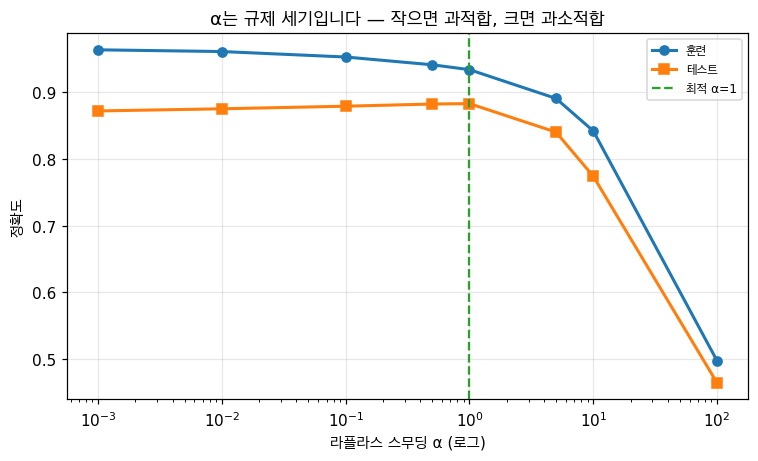

In [6]:
# ✨ 추가 — 원문 연습문제 1번: 실제 데이터에서 α를 훑어 봅니다
from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB

주제 = ["rec.sport.baseball", "sci.space", "talk.politics.guns", "comp.graphics"]
훈련 = fetch_20newsgroups(subset="train", categories=주제,
                         remove=("headers", "footers", "quotes"), random_state=0)
테스트 = fetch_20newsgroups(subset="test", categories=주제,
                           remove=("headers", "footers", "quotes"), random_state=0)
print(f"20 Newsgroups: 훈련 {len(훈련.data)}개, 테스트 {len(테스트.data)}개, 주제 {len(주제)}개")
for i, 이름 in enumerate(훈련.target_names):
    print(f"   {i}: {이름}")

벡터 = CountVectorizer(min_df=2)
X훈련 = 벡터.fit_transform(훈련.data)
X테스트 = 벡터.transform(테스트.data)
print(f"\n어휘 크기: {X훈련.shape[1]:,}")

알파들 = [0.001, 0.01, 0.1, 0.5, 1.0, 5.0, 10.0, 100.0]
print(f"\n{'α':>8}{'훈련 정확도':>13}{'테스트 정확도':>15}   상태")
print("-" * 56)
알파기록 = []
for 알파 in 알파들:
    m = MultinomialNB(alpha=알파).fit(X훈련, 훈련.target)
    tr, te = m.score(X훈련, 훈련.target), m.score(X테스트, 테스트.target)
    알파기록.append((알파, tr, te))

최고알파 = max(알파기록, key=lambda r: r[2])[0]
for 알파, tr, te in 알파기록:
    상태 = "<- 최고" if 알파 == 최고알파 else ("스무딩 부족" if 알파 < 최고알파 else "스무딩 과다")
    print(f"{알파:>8g}{tr:>13.1%}{te:>15.1%}   {상태}")

print(f"\n=> 최적 α = {최고알파:g} (테스트 "
      f"{max(알파기록, key=lambda r: r[2])[2]:.1%})")
print(f"   α={알파들[-1]:g} 로 올리면 {알파기록[-1][2]:.1%} 로 떨어집니다.")
print(f"\n   📗 원문 연습문제 1번: '왜 아주 높은 α 가 해로운가?'")
print(f"   α가 크면 모든 단어 확률이 균등에 가까워집니다. 1/|V| 쪽으로 끌려가죠.")
print(f"   그러면 단어가 클래스를 구별하는 정보가 사라집니다.")
print(f"   10단원의 언어로 말하면 — α는 규제 세기입니다. 크면 편향↑ 분산↓.")

plt.figure(figsize=(7, 4.3))
plt.plot([r[0] for r in 알파기록], [r[1] for r in 알파기록], "o-", lw=2, label="훈련")
plt.plot([r[0] for r in 알파기록], [r[2] for r in 알파기록], "s-", lw=2, label="테스트")
plt.axvline(최고알파, c="tab:green", ls="--", lw=1.5, label=f"최적 α={최고알파:g}")
plt.xscale("log"); plt.xlabel("라플라스 스무딩 α (로그)"); plt.ylabel("정확도")
plt.title("α는 규제 세기입니다 — 작으면 과적합, 크면 과소적합")
plt.legend(fontsize=8); plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()

---

## 4️⃣ 🔑 로그 공간 — 언더플로 막기

> 📗 **원문** — "Log-Space Computation"
>
> 🔗 **앞 절과 이어서** — 3절에서 확률 0 문제를 고쳤습니다.
> 그런데 0이 아닌 작은 확률도 문제입니다.

### ⚠️ 📗 문제

> "Multiplying hundreds of probabilities (each less than 1) causes floating-point underflow.
> The product becomes zero in floating point even though the true value is
> a very small positive number."

### 📗 해법 — 로그를 씌워 곱셈을 덧셈으로

$$\log P(c \mid x_1, \ldots, x_n) = \log P(c) + \sum_i \log P(x_i \mid c)$$

### ⭐ 📗 그리고 공짜로 얻는 것 — 행렬 곱

$$\text{log\_scores} = X \cdot \log\!\mathbf{P}^\top + \log \boldsymbol{\pi}$$

> 📗 원문: "Matrix multiplication. That is why Naive Bayes prediction is so fast --
> it is the same operation as a single-layer linear model."

나이브 베이즈 예측은 1층 선형 모델과 똑같은 연산입니다.
3단원의 로지스틱 회귀와 예측 형태가 같습니다. 학습 방법만 다르죠(세기 vs 최적화).

In [7]:
# ✨ 추가 — ⚠️ 언더플로를 직접 일으켜 봅니다
r = np.random.default_rng(0)
확률들 = r.uniform(0.001, 0.05, 500)       # 문서 하나에 단어 500개, 각 확률이 작습니다

print(f"단어 {len(확률들)}개, 각 확률 {확률들.min():.4f} ~ {확률들.max():.4f}\n")
print(f"{'단어 개수':>10}{'직접 곱하기':>18}{'로그 합':>14}{'로그를 되돌리면':>18}")
print("-" * 62)
for k in [10, 50, 100, 200, 300, 500]:
    곱 = float(np.prod(확률들[:k]))
    로그합 = float(np.sum(np.log(확률들[:k])))
    되돌림 = "underflow" if 곱 == 0.0 else f"{곱:.3e}"
    print(f"{k:>10}{되돌림:>18}{로그합:>14.2f}{f'e^{로그합:.1f}':>18}")

터지는지점 = next(k for k in range(1, 501) if float(np.prod(확률들[:k])) == 0.0)
print(f"\n=> ⚠️ 단어 {터지는지점}개에서 곱이 0이 됩니다. float64 의 한계(약 1e-308)를 넘은 거죠.")
print(f"   진짜 값은 0이 아닌데 컴퓨터에서 0이 됩니다.")
print(f"   그러면 3절의 '0의 저주'가 다시 일어납니다. 모든 클래스가 0이 되어 비교 불가.")
print(f"\n   로그 합은 {float(np.sum(np.log(확률들))):.1f} 로 멀쩡합니다.")
print(f"   그리고 우리는 크기가 아니라 순위만 필요합니다. 로그는 단조 증가라 순위를 보존하죠.")
print(f"\n   💡 문서가 500단어면 흔한 길이입니다. 로그 공간은 선택이 아니라 필수입니다.")

단어 500개, 각 확률 0.0010 ~ 0.0499

     단어 개수            직접 곱하기          로그 합          로그를 되돌리면
--------------------------------------------------------------
        10         6.804e-18        -39.53           e^-39.5
        50         2.522e-85       -194.79          e^-194.8
       100        2.149e-167       -383.77          e^-383.8
       200         underflow       -770.51          e^-770.5
       300         underflow      -1151.77         e^-1151.8
       500         underflow      -1920.01         e^-1920.0

=> ⚠️ 단어 194개에서 곱이 0이 됩니다. float64 의 한계(약 1e-308)를 넘은 거죠.
   진짜 값은 0이 아닌데 컴퓨터에서 0이 됩니다.
   그러면 3절의 '0의 저주'가 다시 일어납니다. 모든 클래스가 0이 되어 비교 불가.

   로그 합은 -1920.0 로 멀쩡합니다.
   그리고 우리는 크기가 아니라 순위만 필요합니다. 로그는 단조 증가라 순위를 보존하죠.

   💡 문서가 500단어면 흔한 길이입니다. 로그 공간은 선택이 아니라 필수입니다.


In [8]:
# ✨ 추가 — 로그 공간 계산이 '행렬 곱'이라는 걸 확인합니다
# 2절의 장난감 데이터를 행렬로 표현합니다
클래스목록 = ["스팸", "정상"]
어휘3 = ["무료", "돈", "회의"]
세기행렬 = np.array([[80, 60, 10], [5, 10, 100]], dtype=float)
알파 = 1.0
스무딩된 = 세기행렬 + 알파
log가능도 = np.log(스무딩된 / 스무딩된.sum(axis=1, keepdims=True))   # (클래스, 단어)
log사전 = np.log(np.array([0.4, 0.6]))

X = np.array([[2, 1, 0],          # 메일 1: 무료2 돈1
              [0, 0, 5],          # 메일 2: 회의5
              [1, 1, 1]])         # 메일 3: 각 1번

점수행렬 = X @ log가능도.T + log사전      # ⭐ 이게 전부입니다. 행렬 곱 한 번
예측 = 점수행렬.argmax(axis=1)

print("log가능도 행렬 (클래스 × 단어)")
print(f"{'':>6}" + "".join(f"{w:>10}" for w in 어휘3))
for i, c in enumerate(클래스목록):
    print(f"{c:>5}" + "".join(f"{v:>10.4f}" for v in log가능도[i]))
print(f"\nlog사전 = {log사전}")

print(f"\n점수 = X @ log가능도.T + log사전")
print(f"{'메일':>6}{'내용':>22}{'log P(스팸)':>14}{'log P(정상)':>14}{'예측':>8}")
print("-" * 66)
for i in range(len(X)):
    내용 = ", ".join(f"{w}×{int(c)}" for w, c in zip(어휘3, X[i]) if c > 0)
    print(f"{i+1:>6}{내용:>22}{점수행렬[i,0]:>14.3f}{점수행렬[i,1]:>14.3f}"
          f"{클래스목록[예측[i]]:>8}")

print(f"\n=> 메일 {len(X)}개를 한 번의 행렬 곱으로 전부 예측했습니다.")
print(f"   📗 원문: 'it is the same operation as a single-layer linear model'")
print(f"\n   3단원의 로지스틱 회귀와 비교해 보세요.")
print(f"   · 로지스틱: 점수 = X @ w + b   (w 를 경사하강법으로 학습)")
print(f"   · 나이브 베이즈: 점수 = X @ log가능도.T + log사전   (세기만 해서 구함)")
print(f"   예측 형태가 같습니다. 둘 다 선형 분류기입니다. 8절에서 다시 비교합니다.")

log가능도 행렬 (클래스 × 단어)
              무료         돈        회의
   스팸   -0.6360   -0.9196   -2.6325
   정상   -2.9789   -2.3728   -0.1556

log사전 = [-0.9163 -0.5108]

점수 = X @ log가능도.T + log사전
    메일                    내용     log P(스팸)     log P(정상)      예측
------------------------------------------------------------------
     1             무료×2, 돈×1        -3.108        -8.841      스팸
     2                  회의×5       -14.079        -1.289      정상
     3       무료×1, 돈×1, 회의×1        -5.104        -6.018      스팸

=> 메일 3개를 한 번의 행렬 곱으로 전부 예측했습니다.
   📗 원문: 'it is the same operation as a single-layer linear model'

   3단원의 로지스틱 회귀와 비교해 보세요.
   · 로지스틱: 점수 = X @ w + b   (w 를 경사하강법으로 학습)
   · 나이브 베이즈: 점수 = X @ log가능도.T + log사전   (세기만 해서 구함)
   예측 형태가 같습니다. 둘 다 선형 분류기입니다. 8절에서 다시 비교합니다.


---

## 5️⃣ 🔨 MultinomialNB 밑바닥부터

> 📗 **원문** — "Build It: MultinomialNB" + "Three Variants: Multinomial"
>
> 🔗 **앞 절과 이어서** — 3절(스무딩)과 4절(로그 공간)을 합치면 만들 수 있습니다.

### 📗 Multinomial 은 특징을 **횟수**로 봅니다

$$P(w_i \mid c) = \frac{\text{count}(w_i, c) + \alpha}{\text{total}(c) + \alpha \cdot |V|}$$

**텍스트의 기본 선택**입니다. 단어 빈도나 TF-IDF 값에 씁니다.

### 🔨 학습은 세 줄입니다

1. 클래스별 **문서 수**를 세서 사전확률
2. 클래스별 **단어 횟수 합**을 세서 가능도
3. 둘에 **로그**를 씌워 저장

**끝입니다.** 반복도 최적화도 없습니다. 📗 원문: "Training is a single pass through the data."

In [9]:
# 📗 원문 Build It — MultinomialNB
class 다항NB:
    def __init__(self, 알파=1.0):
        self.알파 = 알파

    def fit(self, X, y):
        X = np.asarray(X, dtype=float) if not hasattr(X, "toarray") else X
        y = np.asarray(y)
        self.클래스 = np.unique(y)
        n, d = X.shape

        # ① 사전확률: 클래스별 문서 비율
        클래스별개수 = np.array([float((y == c).sum()) for c in self.클래스])
        self.log사전 = np.log(클래스별개수 / n)

        # ② 가능도: 클래스별 단어 횟수 합 + 스무딩
        단어합 = np.zeros((len(self.클래스), d))
        for i, c in enumerate(self.클래스):
            골라 = X[y == c]
            단어합[i] = np.asarray(골라.sum(axis=0)).ravel()
        스무딩 = 단어합 + self.알파
        # ③ 로그를 씌워 저장 (4절)
        self.log가능도 = np.log(스무딩 / 스무딩.sum(axis=1, keepdims=True))
        return self

    def 결정값(self, X):
        # ⭐ 4절에서 본 행렬 곱 하나
        return np.asarray(X @ self.log가능도.T) + self.log사전

    def predict(self, X):
        return self.클래스[self.결정값(X).argmax(axis=1)]

    def predict_log_proba(self, X):
        점수 = self.결정값(X)
        # log-sum-exp 로 정규화 (여기서도 언더플로를 막습니다)
        최대 = 점수.max(axis=1, keepdims=True)
        로그합 = 최대 + np.log(np.exp(점수 - 최대).sum(axis=1, keepdims=True))
        return 점수 - 로그합

    def predict_proba(self, X):
        return np.exp(self.predict_log_proba(X))

    def score(self, X, y):
        return float(np.mean(self.predict(X) == np.asarray(y)))

print("다항NB 준비 완료 — 학습 코드가 10줄입니다")

다항NB 준비 완료 — 학습 코드가 10줄입니다


In [10]:
# 직접 만든 것과 sklearn 이 같은 답을 내는지
내것 = 다항NB(알파=0.1).fit(X훈련, 훈련.target)
sk것 = MultinomialNB(alpha=0.1).fit(X훈련, 훈련.target)

print(f"{'구현':<22}{'훈련 정확도':>12}{'테스트 정확도':>14}")
print("-" * 50)
print(f"{'직접 만든 것 (5절)':<20}{내것.score(X훈련, 훈련.target):>12.1%}"
      f"{내것.score(X테스트, 테스트.target):>14.1%}")
print(f"{'sklearn MultinomialNB':<21}{sk것.score(X훈련, 훈련.target):>12.1%}"
      f"{sk것.score(X테스트, 테스트.target):>14.1%}")

print(f"\n예측이 일치하는 비율: "
      f"{np.mean(내것.predict(X테스트) == sk것.predict(X테스트)):.2%}")
print(f"log가능도 최대 차이: "
      f"{np.abs(내것.log가능도 - sk것.feature_log_prob_).max():.2e}")
print(f"log사전 최대 차이  : {np.abs(내것.log사전 - sk것.class_log_prior_).max():.2e}")
print("\n=> 완전히 같습니다. 10줄로 sklearn MultinomialNB 를 재현했습니다.")

# 각 클래스의 '대표 단어' 를 뽑아 봅니다
이름들 = 벡터.get_feature_names_out()
print(f"\n[각 주제에서 log가능도가 가장 높은 단어 — 모델이 뭘 배웠나]")
for i, c in enumerate(내것.클래스):
    # 다른 클래스 대비 상대적으로 높은 단어를 봅니다 (흔한 단어 제외 효과)
    상대 = 내것.log가능도[i] - 내것.log가능도.mean(axis=0)
    상위 = np.argsort(상대)[::-1][:8]
    print(f"   {훈련.target_names[c][:28]:<30} {', '.join(이름들[j] for j in 상위)}")
print("\n=> 모델이 주제별 특징 단어를 제대로 찾았습니다. 세기만 했는데도요.")

구현                          훈련 정확도       테스트 정확도
--------------------------------------------------
직접 만든 것 (5절)               95.3%         87.9%
sklearn MultinomialNB       95.3%         87.9%

예측이 일치하는 비율: 100.00%
log가능도 최대 차이: 1.78e-15
log사전 최대 차이  : 2.22e-16

=> 완전히 같습니다. 10줄로 sklearn MultinomialNB 를 재현했습니다.

[각 주제에서 log가능도가 가장 높은 단어 — 모델이 뭘 배웠나]
   comp.graphics                  tiff, 3d, animation, visualization, polygon, vga, viewer, vesa
   rec.sport.baseball             season, pitching, braves, sox, pitcher, hitter, alomar, phillies
   sci.space                      lunar, spacecraft, orbital, orbit, km, orbiter, titan, russian
   talk.politics.guns             firearms, firearm, fbi, militia, amendment, guns, criminals, assault

=> 모델이 주제별 특징 단어를 제대로 찾았습니다. 세기만 했는데도요.


---

## 6️⃣ 🔨 GaussianNB 밑바닥부터

> 📗 **원문** — "Build It: GaussianNB" + "Three Variants: Gaussian"
>
> 🔗 **앞 절과 이어서** — 5절은 **횟수** 데이터용이었습니다.
> 키·몸무게·센서값 같은 **연속값**에는 쓸 수 없습니다. 음수도 나오고, 소수점도 나오니까요.

### 📗 Gaussian 은 특징을 **정규분포**로 봅니다

$$P(x_i \mid c) = \frac{1}{\sqrt{2\pi\sigma_{c,i}^2}} \exp\left(-\frac{(x_i - \mu_{c,i})^2}{2\sigma_{c,i}^2}\right)$$

클래스마다, 특징마다 자기 평균과 분산을 가집니다.

### 🧸 비유 — 키로 성별 맞히기

남성의 키는 평균 174cm, 표준편차 6cm. 여성은 평균 161cm, 표준편차 5.5cm.
**키 180cm인 사람**이 왔습니다.

- 남성 분포에서 180이 나올 밀도 = 높음
- 여성 분포에서 180이 나올 밀도 = 아주 낮음

밀도가 높은 쪽을 고릅니다. 이게 GaussianNB 전부입니다.

### ⚠️ 📗 주의 — 분산이 0이면 터집니다

> "GaussianNB divides by variance. If a feature has zero variance for a class
> (all values identical), the probability computation breaks.
> The code adds a small smoothing term (1e-9) to all variances."

### 🔑 7단원 6절의 GMM 과 무엇이 다른가요?

거의 같습니다. 둘 다 클래스별 정규분포를 씁니다. 차이는 **두 가지**입니다.

| | GaussianNB (이 절) | GMM (7단원 6절) |
| --- | --- | --- |
| 라벨 | **있습니다** (지도 학습) | 없습니다 (비지도) |
| 공분산 | **대각만** (독립 가정!) | **전체 행렬** (상관 허용) |

> "독립 가정"이 공분산 행렬에서는 "대각 행렬"로 나타납니다.
> 특징 간 상관을 0으로 못 박는 거죠. 아래에서 그 차이를 그림으로 봅니다.

In [11]:
# 📗 원문 Build It — GaussianNB
class 가우시안NB:
    def __init__(self, 분산보정=1e-9):
        self.분산보정 = 분산보정

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y)
        self.클래스 = np.unique(y)
        n, d = X.shape

        self.평균 = np.zeros((len(self.클래스), d))
        self.분산 = np.zeros((len(self.클래스), d))
        self.log사전 = np.zeros(len(self.클래스))

        for i, c in enumerate(self.클래스):
            골라 = X[y == c]
            self.평균[i] = 골라.mean(axis=0)
            # ⚠️ 분산이 0이면 나눗셈이 터집니다. 전체 분산의 일부를 더해 줍니다
            self.분산[i] = 골라.var(axis=0) + self.분산보정 * X.var(axis=0).max()
            self.log사전[i] = math.log(len(골라) / n)
        return self

    def 결정값(self, X):
        X = np.asarray(X, dtype=float)
        점수 = np.zeros((len(X), len(self.클래스)))
        for i in range(len(self.클래스)):
            # log N(x; μ, σ²) = -0.5·log(2πσ²) - (x-μ)²/(2σ²), 특징마다 더합니다
            앞 = -0.5 * np.log(2 * np.pi * self.분산[i])
            뒤 = -0.5 * ((X - self.평균[i]) ** 2) / self.분산[i]
            점수[:, i] = self.log사전[i] + (앞 + 뒤).sum(axis=1)
        return 점수

    def predict(self, X):
        return self.클래스[self.결정값(X).argmax(axis=1)]

    def predict_proba(self, X):
        점수 = self.결정값(X)
        최대 = 점수.max(axis=1, keepdims=True)
        e = np.exp(점수 - 최대)
        return e / e.sum(axis=1, keepdims=True)

    def score(self, X, y):
        return float(np.mean(self.predict(X) == np.asarray(y)))


from sklearn.datasets import load_iris, load_wine
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB

for 이름, 불러오기 in [("Iris", load_iris), ("Wine", load_wine)]:
    d = 불러오기()
    Xa, Xb, ya, yb = train_test_split(d.data, d.target, test_size=0.3,
                                      random_state=0, stratify=d.target)
    내G = 가우시안NB().fit(Xa, ya)
    skG = GaussianNB().fit(Xa, ya)
    print(f"[{이름}] {d.data.shape[0]}행 × {d.data.shape[1]}열, 클래스 {len(d.target_names)}개")
    print(f"   직접 만든 것 {내G.score(Xb, yb):.1%}   sklearn {skG.score(Xb, yb):.1%}   "
          f"예측 일치 {np.mean(내G.predict(Xb) == skG.predict(Xb)):.1%}")
    print(f"   평균 최대 차이 {np.abs(내G.평균 - skG.theta_).max():.2e}   "
          f"분산 최대 차이 {np.abs(내G.분산 - skG.var_).max():.2e}")

print("\n=> sklearn 과 일치합니다. (분산 보정 방식이 조금 달라 미세한 차이가 날 수 있습니다)")

[Iris] 150행 × 4열, 클래스 3개
   직접 만든 것 97.8%   sklearn 97.8%   예측 일치 100.0%
   평균 최대 차이 0.00e+00   분산 최대 차이 0.00e+00
[Wine] 178행 × 13열, 클래스 3개
   직접 만든 것 96.3%   sklearn 96.3%   예측 일치 100.0%
   평균 최대 차이 0.00e+00   분산 최대 차이 0.00e+00

=> sklearn 과 일치합니다. (분산 보정 방식이 조금 달라 미세한 차이가 날 수 있습니다)


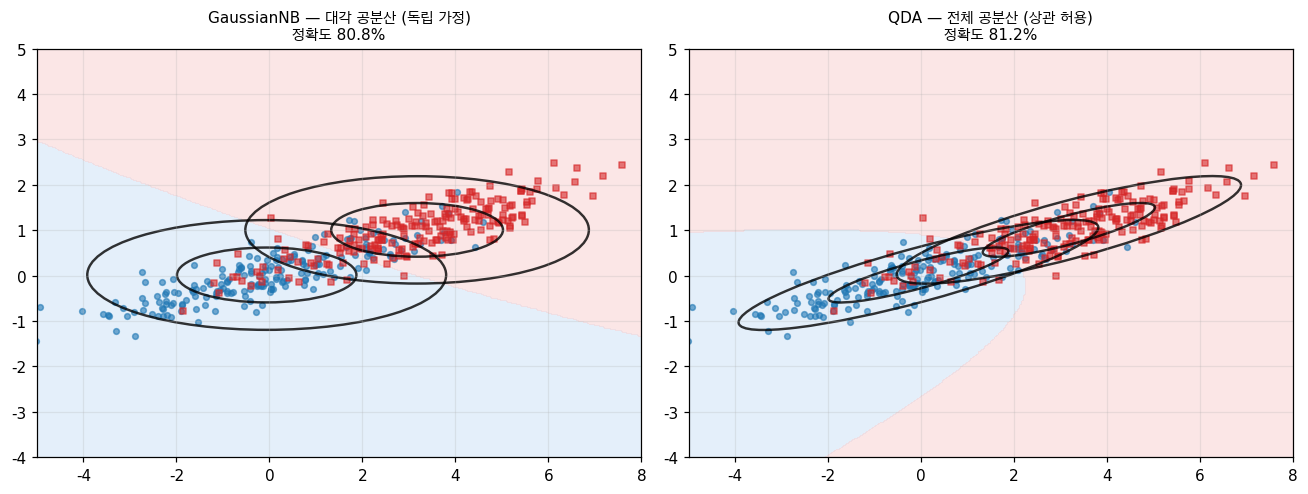

GaussianNB (대각)  정확도 80.8%
QDA (전체 공분산)  정확도 81.2%

=> 검은 타원을 보세요.
   · GaussianNB: 타원이 축에 나란합니다. 상관을 0으로 못 박았으니까요
   · QDA: 타원이 데이터처럼 기울어져 있습니다. 상관을 학습했죠

   이게 독립 가정의 기하학적 의미입니다. 7단원 6절 GMM의 타원과 비교해 보세요.
   ⚠️ 그런데 정확도 차이는 0.4%p 뿐입니다.
      틀린 모양으로도 경계는 비슷하게 긋습니다. 1절의 '순위만 맞으면 된다' 입니다.


In [12]:
# ✨ 추가 — '독립 가정 = 대각 공분산' 을 그림으로 확인합니다
from matplotlib.patches import Ellipse
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis

# 특징 두 개가 강하게 상관된 데이터를 만듭니다
rng = np.random.default_rng(0)
기울이기 = np.array([[1.0, 0.0], [1.6, 0.6]])
A = rng.normal(size=(200, 2)) @ 기울이기 + [0, 0]
B = rng.normal(size=(200, 2)) @ 기울이기 + [3.2, 1.0]
X상관 = np.vstack([A, B]); y상관 = np.array([0]*200 + [1]*200)

내G2 = 가우시안NB().fit(X상관, y상관)
QDA = QuadraticDiscriminantAnalysis(store_covariance=True).fit(X상관, y상관)   # 전체 공분산을 쓰는 버전

fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
격자 = np.linspace(-5, 8, 300)
G1, G2 = np.meshgrid(격자, np.linspace(-4, 5, 300))
격자점 = np.c_[G1.ravel(), G2.ravel()]

for a_, (이름, 모델, 공분산들) in zip(ax, [
        ("GaussianNB — 대각 공분산 (독립 가정)", 내G2,
         [np.diag(내G2.분산[i]) for i in range(2)]),
        ("QDA — 전체 공분산 (상관 허용)", QDA, list(QDA.covariance_))]):
    Z = 모델.predict(격자점).reshape(G1.shape)
    a_.contourf(G1, G2, Z, levels=[-0.5, 0.5, 1.5],
                colors=["#cfe3f7", "#f9d3d3"], alpha=0.55)
    for 라벨, c, mk in [(0, "tab:blue", "o"), (1, "tab:red", "s")]:
        a_.scatter(X상관[y상관 == 라벨, 0], X상관[y상관 == 라벨, 1],
                   s=14, c=c, marker=mk, alpha=0.6)
    평균들 = 내G2.평균 if 모델 is 내G2 else QDA.means_
    for i in range(2):
        값, 고유벡터 = np.linalg.eigh(공분산들[i])
        각 = math.degrees(math.atan2(고유벡터[1, -1], 고유벡터[0, -1]))
        for 배수 in (1, 2):
            a_.add_patch(Ellipse(평균들[i], *(2 * 배수 * np.sqrt(값[::-1])), angle=각,
                                 fill=False, color="black", lw=1.6, alpha=0.8))
    맞음 = 모델.score(X상관, y상관)
    a_.set_title(f"{이름}\n정확도 {맞음:.1%}", fontsize=10)
    a_.set_xlim(-5, 8); a_.set_ylim(-4, 5); a_.grid(alpha=0.25)
plt.tight_layout(); plt.show()

G점수 = 내G2.score(X상관, y상관)
Q점수 = QDA.score(X상관, y상관)
print(f"GaussianNB (대각)  정확도 {G점수:.1%}")
print(f"QDA (전체 공분산)  정확도 {Q점수:.1%}")
print(f"\n=> 검은 타원을 보세요.")
print(f"   · GaussianNB: 타원이 축에 나란합니다. 상관을 0으로 못 박았으니까요")
print(f"   · QDA: 타원이 데이터처럼 기울어져 있습니다. 상관을 학습했죠")
print(f"\n   이게 독립 가정의 기하학적 의미입니다. 7단원 6절 GMM의 타원과 비교해 보세요.")
차이 = abs(round(G점수 * 100, 1) - round(Q점수 * 100, 1))
print(f"   ⚠️ 그런데 정확도 차이는 {차이:.1f}%p 뿐입니다.")
print(f"      틀린 모양으로도 경계는 비슷하게 긋습니다. 1절의 '순위만 맞으면 된다' 입니다.")

---

## 7️⃣ ⚠️ 독립 가정이 얼마나 틀렸나

> 📗 **원문** — 연습문제 2번 + "Why It Still Works"
>
> 🔗 1절로 되돌아갑니다 — 1절에서 "거짓말을 한다"고 했습니다.
> 5·6절에서 모델을 만들었으니, 이제 그 거짓말의 크기를 재 봅니다.

### 📐 측정 방법

독립 가정이 맞다면 이 등식이 성립해야 합니다.

$$P(w_1 \cap w_2 \mid c) \stackrel{?}{=} P(w_1 \mid c) \cdot P(w_2 \mid c)$$

왼쪽(실제 공존 비율)과 오른쪽(독립 가정)을 직접 세서 비교하면 됩니다.

### 🧸 왜 이걸 재야 하나요?

"가정이 틀렸다"는 말만 들으면 **얼마나 틀렸는지** 감이 안 옵니다.
2배 틀렸나, 100배 틀렸나? 재 보면 압니다.

그리고 더 중요한 질문이 남습니다: 그만큼 틀렸는데 왜 분류는 되나?

In [13]:
# ✨ 추가 — 원문 연습문제 2번: 독립 가정이 실제로 얼마나 틀렸나
X이진 = (X훈련 > 0).toarray()          # 문서에 단어가 있나/없나
이름목록 = list(벡터.get_feature_names_out())
자리 = {w: i for i, w in enumerate(이름목록)}

쌍들 = [("space", "nasa"), ("orbit", "shuttle"), ("baseball", "game"),
        ("gun", "guns"), ("image", "file"), ("space", "baseball")]
쌍들 = [(a, b) for a, b in 쌍들 if a in 자리 and b in 자리]

print("각 주제 안에서 두 단어가 같이 나오는 비율을 재 봅니다\n")
print(f"{'단어 쌍':<22}{'주제':<28}{'실제 P(둘다)':>13}{'독립 가정':>11}{'비율':>9}")
print("-" * 86)
비율들 = []
for a, b in 쌍들:
    i, j = 자리[a], 자리[b]
    for c in 내것.클래스:
        m = 훈련.target == c
        p1 = X이진[m, i].mean()
        p2 = X이진[m, j].mean()
        p12 = (X이진[m, i] & X이진[m, j]).mean()
        독립 = p1 * p2
        if 독립 < 1e-4 or p12 < 1e-4:
            continue                       # 둘 중 하나가 거의 안 나오는 주제는 건너뜁니다
        비 = p12 / 독립
        비율들.append((f"{a}+{b}", 훈련.target_names[c], p12, 독립, 비))
        print(f"{f'{a} & {b}':<21}{훈련.target_names[c][:26]:<28}"
              f"{p12:>13.4f}{독립:>11.4f}{비:>8.1f}배")

# 비율이 가장 큰 쌍을 그냥 뽑으면 '둘 다 아주 드문 주제'가 1등으로 올라옵니다.
# 그런 줄은 표본이 적어서 비율이 과장됩니다. 두 가지를 나눠서 봅니다.
흔한것 = [r for r in 비율들 if r[2] >= 0.03]      # 열 문서 중 세 번 이상 같이 나오는 쌍
드문것 = [r for r in 비율들 if r[2] < 0.03]
대표 = max(흔한것, key=lambda r: r[4])
정확도 = 내것.score(X테스트, 테스트.target)
두단어 = 대표[0].split("+")

print(f"\n=> ⚠️ 둘 다 흔한 쌍 중에서 독립 가정이 가장 크게 틀린 것은 "
      f"{대표[4]:.1f}배입니다.")
print(f"   '{두단어[0]}'와 '{두단어[1]}' / {대표[1]} 주제")
print(f"   실제로는 {대표[2]:.1%} 문서에서 같이 나오는데, "
      f"독립 가정은 {대표[3]:.1%} 라고 봅니다.")
print(f"   당연히 같이 나오는 단어인데 모델은 서로 모르는 사이라고 믿는 거죠.")

if 드문것:
    드문최대 = max(드문것, key=lambda r: r[4])
    드문단어 = 드문최대[0].split("+")
    print(f"\n   표에서 비율이 {드문최대[4]:.0f}배까지 가는 줄도 있습니다 "
          f"('{드문단어[0]}'와 '{드문단어[1]}' / {드문최대[1]}).")
    print(f"   그런데 같이 나오는 비율 자체가 {드문최대[2]:.1%} 뿐입니다. "
          f"드문 단어라 비율이 과장된 거죠.")
    print(f"   그래서 '최대 몇 배'를 말할 때는 흔한 쌍만 보는 게 정직합니다.")

print(f"\n   그런데 5절의 모델은 테스트 정확도 {정확도:.1%} 입니다.")
print(f"   {대표[4]:.1f}배 틀린 가정으로 {정확도:.0%}를 맞힙니다.")
print(f"\n   📗 원문의 설명 ③번이 답입니다. 중복 계산이 맞는 클래스에도 일어납니다.")
print(f"   '{두단어[0]}'와 '{두단어[1]}'이 같이 나오면 NB는 그 주제 증거를 두 번 셉니다.")
print(f"   과장이지만 방향이 맞습니다. 다른 주제에는 둘 다 잘 안 나오니까요.")
print(f"   => 점수는 과장되고, 순위는 보존됩니다.")

각 주제 안에서 두 단어가 같이 나오는 비율을 재 봅니다

단어 쌍                  주제                               실제 P(둘다)      독립 가정       비율
--------------------------------------------------------------------------------------
space & nasa         comp.graphics                      0.0103     0.0005    21.9배
space & nasa         sci.space                          0.1197     0.0639     1.9배
orbit & shuttle      sci.space                          0.0320     0.0148     2.2배
baseball & game      rec.sport.baseball                 0.0452     0.0273     1.7배
gun & guns           talk.politics.guns                 0.1264     0.0592     2.1배
image & file         comp.graphics                      0.0462     0.0190     2.4배
image & file         sci.space                          0.0084     0.0004    21.8배

=> ⚠️ 둘 다 흔한 쌍 중에서 독립 가정이 가장 크게 틀린 것은 2.4배입니다.
   'image'와 'file' / comp.graphics 주제
   실제로는 4.6% 문서에서 같이 나오는데, 독립 가정은 1.9% 라고 봅니다.
   당연히 같이 나오는 단어인데 모델은 서로 모르는 사이라고 믿는 거죠.

   표에서 비율이 22배까지 가는 줄도 있습니다 ('space'와 '

---

## 8️⃣ 🔑 NB vs 로지스틱 회귀

> 📗 **원문** — "Naive Bayes vs Logistic Regression"
>
> 🔗 **앞 절과 이어서** — 7절에서 가정이 크게 틀렸는데도 잘 된다는 걸 봤습니다.
> 그럼 **가정을 안 하는 모델**과 비교하면 어떨까요?
> 4절에서 봤듯 둘 다 **선형 분류기**입니다. 학습 방법만 다릅니다.

### 📗 핵심 차이 — 생성 vs 판별

| 항목 | 나이브 베이즈 | 로지스틱 회귀 |
| --- | --- | --- |
| **종류** | **생성 모델** ($P(X \mid Y)$ 를 모델링) | **판별 모델** ($P(Y \mid X)$ 를 직접) |
| 학습 | **빈도 세기** | 손실 함수 최적화 |
| **데이터 적을 때** | **더 좋음** (강한 사전지식이 도움) | 더 나쁨 (가중치 추정에 데이터 부족) |
| **데이터 많을 때** | 더 나쁨 (틀린 가정이 발목) | **더 좋음** (유연한 경계) |
| 특징 | 독립 가정 | **상관을 다룸** |
| 속도 | 한 번 훑기, **매우 빠름** | 반복 최적화 |
| 확률 보정 | **나쁨** | 더 좋음 |

### 🧸 비유 — 생성 vs 판별

고양이와 강아지를 구별하는 두 방법입니다.

- **생성 모델 (NB)**: **"고양이는 이렇게 생겼다"**를 배웁니다. 그리고 새 사진이 어느 쪽 설명에 더 맞는지 봅니다. 고양이를 그릴 수도 있죠.
- **판별 모델 (LR)**: "고양이와 강아지를 가르는 선"만 배웁니다. 고양이가 어떻게 생겼는지는 모릅니다. 구별만 합니다.

> 📗 **경험 규칙**: "start with Naive Bayes. If you have enough data and NB plateaus,
> switch to logistic regression."
>
> 원문 연습문제 4번이 바로 이걸 재 보라고 합니다. 해 봅니다.

20 Newsgroups 4개 주제, 어휘 13,350개

     훈련 개수   MultinomialNB        로지스틱 회귀     NB 우위
------------------------------------------------------
        50           56.0%          43.5%    +12.5%
       100           72.2%          47.8%    +24.4%
       200           74.9%          56.9%    +17.9%
       500           83.5%          67.5%    +16.0%
      1000           86.4%          75.3%    +11.1%
      1500           87.5%          77.5%    +10.0%
      2320           87.9%          80.0%     +7.9%

=> 'NB 우위' 열을 보세요. 50개에서 +12.5%p, 2320개에서 +7.9%p
   격차가 1.6배 줄어듭니다.
   📗 원문의 '작은 데이터는 NB, 큰 데이터는 LR' 의 방향은 확인됩니다.

   ⚠️ 그런데 역전은 안 일어났습니다. 끝까지 NB가 +7.9%p 앞섭니다.
      📗 원문 연습문제 4번은 'At what point does LR overtake NB?' 라고 묻는데,
      이 데이터에서는 그 지점이 없습니다. 아래에서 더 밀어붙여 봅니다.


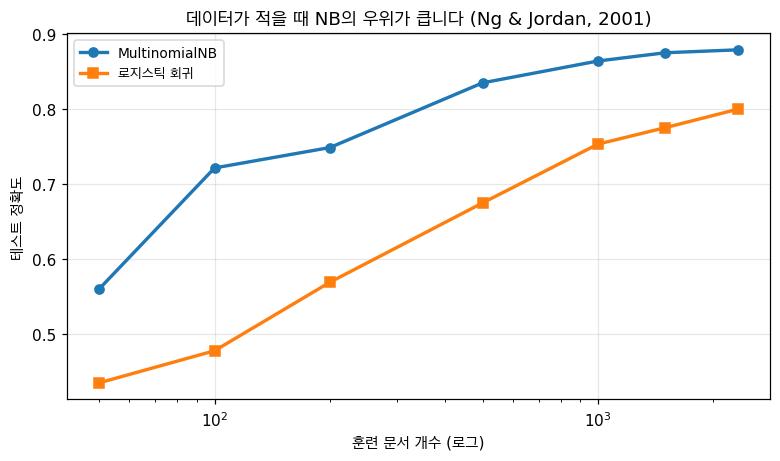

In [14]:
# ✨ 추가 — 원문 연습문제 4번: 훈련 데이터를 늘려 가며 NB vs LR
from sklearn.linear_model import LogisticRegression

rng = np.random.default_rng(0)
순서 = rng.permutation(len(훈련.data))
크기들 = [50, 100, 200, 500, 1000, 1500, len(훈련.data)]

print(f"20 Newsgroups {len(주제)}개 주제, 어휘 {X훈련.shape[1]:,}개\n")
print(f"{'훈련 개수':>10}{'MultinomialNB':>16}{'로지스틱 회귀':>15}{'NB 우위':>10}")
print("-" * 54)
곡선 = []
for n in 크기들:
    칸 = 순서[:n]
    if len(np.unique(훈련.target[칸])) < len(주제):
        continue
    nb = MultinomialNB(alpha=0.1).fit(X훈련[칸], 훈련.target[칸]).score(X테스트, 테스트.target)
    lr = (LogisticRegression(max_iter=3000)
          .fit(X훈련[칸], 훈련.target[칸]).score(X테스트, 테스트.target))
    곡선.append((n, nb, lr))
    print(f"{n:>10}{nb:>16.1%}{lr:>15.1%}{nb-lr:>+10.1%}")

처음, 마지막 = 곡선[0], 곡선[-1]
print(f"\n=> 'NB 우위' 열을 보세요. {처음[0]}개에서 {처음[1]-처음[2]:+.1%}p,"
      f" {마지막[0]}개에서 {마지막[1]-마지막[2]:+.1%}p")
print(f"   격차가 {abs(처음[1]-처음[2])/max(abs(마지막[1]-마지막[2]),1e-9):.1f}배 줄어듭니다.")
print(f"   📗 원문의 '작은 데이터는 NB, 큰 데이터는 LR' 의 방향은 확인됩니다.")
print(f"\n   ⚠️ 그런데 역전은 안 일어났습니다. 끝까지 NB가 {마지막[1]-마지막[2]:+.1%}p 앞섭니다.")
print(f"      📗 원문 연습문제 4번은 'At what point does LR overtake NB?' 라고 묻는데,")
print(f"      이 데이터에서는 그 지점이 없습니다. 아래에서 더 밀어붙여 봅니다.")

plt.figure(figsize=(7.2, 4.3))
plt.plot([c[0] for c in 곡선], [c[1] for c in 곡선], "o-", lw=2.2, label="MultinomialNB")
plt.plot([c[0] for c in 곡선], [c[2] for c in 곡선], "s-", lw=2.2, label="로지스틱 회귀")
plt.xscale("log"); plt.xlabel("훈련 문서 개수 (로그)"); plt.ylabel("테스트 정확도")
plt.title("데이터가 적을 때 NB의 우위가 큽니다 (Ng & Jordan, 2001)")
plt.legend(fontsize=9); plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()

In [15]:
# ⚠️ 추가 — 데이터를 5배로 늘리고 LR을 튜닝해도 역전이 안 되는지
from sklearn.feature_extraction.text import TfidfVectorizer

훈련전체 = fetch_20newsgroups(subset="train", remove=("headers", "footers", "quotes"),
                            random_state=0)
테스트전체 = fetch_20newsgroups(subset="test", remove=("headers", "footers", "quotes"),
                              random_state=0)
v전체 = TfidfVectorizer(min_df=2)
A = v전체.fit_transform(훈련전체.data)
B = v전체.transform(테스트전체.data)
print(f"20개 주제 전체: 훈련 {A.shape[0]:,}행 × {A.shape[1]:,}열 "
      f"(앞 실험보다 {A.shape[0]/len(훈련.data):.1f}배)\n")

print(f"{'모델':<26}{'테스트 정확도':>14}")
print("-" * 42)
전체결과 = []
for 이름, m in [("MultinomialNB α=0.01", MultinomialNB(alpha=0.01)),
                ("MultinomialNB α=0.1", MultinomialNB(alpha=0.1)),
                ("로지스틱 C=1", LogisticRegression(max_iter=3000)),
                ("로지스틱 C=10", LogisticRegression(max_iter=3000, C=10)),
                ("로지스틱 C=100", LogisticRegression(max_iter=3000, C=100))]:
    점 = m.fit(A, 훈련전체.target).score(B, 테스트전체.target)
    전체결과.append((이름, 점))
    print(f"{이름:<25}{점:>14.1%}")

NB최고 = max([r for r in 전체결과 if "NB" in r[0]], key=lambda r: r[1])
LR최고 = max([r for r in 전체결과 if "로지스틱" in r[0]], key=lambda r: r[1])
print(f"\nNB 최고: {NB최고[0]} {NB최고[1]:.1%}")
print(f"LR 최고: {LR최고[0]} {LR최고[1]:.1%}")
print(f"차이: {NB최고[1]-LR최고[1]:+.1%}p")

if NB최고[1] > LR최고[1]:
    print(f"\n=> ⚠️ 훈련 {A.shape[0]:,}개에 LR의 C까지 튜닝했는데도 NB가 이깁니다.")
    print(f"   📗 원문 표의 'Large data: NB worse, LR better' 는 이 데이터에서 재현되지 않습니다.")
    print(f"\n   왜일까요? 텍스트의 특수성 때문입니다.")
    print(f"   · 특징이 {A.shape[1]:,}개인데 샘플이 {A.shape[0]:,}개입니다. "
          f"여전히 특징이 샘플의 {A.shape[1]/A.shape[0]:.1f}배입니다")
    print(f"   · 📗 원문도 'these failure modes are rare for text classification' 이라고 인정합니다")
    print(f"   · 'Large data' 가 되려면 샘플이 특징보다 훨씬 많아야 합니다 (수십만~수백만 문서)")
    print(f"\n   💡 실무 결론은 그대로 유효합니다 — 텍스트면 NB부터 시작하세요.")
    print(f"      그리고 '큰 데이터에서는 LR이 낫다'는 말을 들으면")
    print(f"      '얼마나 커야 큰 건가'를 되물어 보세요. 재 보면 생각보다 훨씬 커야 합니다.")
else:
    print(f"\n=> 📗 원문 주장대로 LR이 역전했습니다.")

20개 주제 전체: 훈련 11,314행 × 39,423열 (앞 실험보다 4.9배)

모델                               테스트 정확도
------------------------------------------
MultinomialNB α=0.01              69.6%
MultinomialNB α=0.1               69.7%
로지스틱 C=1                          67.4%
로지스틱 C=10                         68.0%
로지스틱 C=100                        67.5%

NB 최고: MultinomialNB α=0.1 69.7%
LR 최고: 로지스틱 C=10 68.0%
차이: +1.7%p

=> ⚠️ 훈련 11,314개에 LR의 C까지 튜닝했는데도 NB가 이깁니다.
   📗 원문 표의 'Large data: NB worse, LR better' 는 이 데이터에서 재현되지 않습니다.

   왜일까요? 텍스트의 특수성 때문입니다.
   · 특징이 39,423개인데 샘플이 11,314개입니다. 여전히 특징이 샘플의 3.5배입니다
   · 📗 원문도 'these failure modes are rare for text classification' 이라고 인정합니다
   · 'Large data' 가 되려면 샘플이 특징보다 훨씬 많아야 합니다 (수십만~수백만 문서)

   💡 실무 결론은 그대로 유효합니다 — 텍스트면 NB부터 시작하세요.
      그리고 '큰 데이터에서는 LR이 낫다'는 말을 들으면
      '얼마나 커야 큰 건가'를 되물어 보세요. 재 보면 생각보다 훨씬 커야 합니다.


---

## 9️⃣ 세 변종 비교 (+ ⚠️ 원문 검증)

> 📗 **원문** — "Three Variants" + "When to Use Each Variant" + "BernoulliNB for Short Text"
>
> 🔗 5·6절에서 둘을 만들었습니다 — Multinomial(횟수)과 Gaussian(연속값).
> 세 번째가 **Bernoulli**(있나/없나)입니다.

### 📗 Bernoulli 는 특징을 **이진**으로 봅니다

$$P(w_i \mid c) = \frac{\text{그 단어가 든 문서 수} + \alpha}{\text{클래스 문서 수} + 2\alpha}$$

### ⭐ 📗 Multinomial 과의 결정적 차이

> "Unlike Multinomial, Bernoulli explicitly penalizes the absence of a word.
> If '무료' typically appears in spam but is absent from this email,
> Bernoulli counts that as evidence against spam."

2절에서 "없는 단어는 영향이 없다"고 했죠? Bernoulli는 영향이 있습니다.
"스팸에 흔한 단어가 없다"는 것도 증거로 씁니다.

### 📗 변종 선택 표

| 변종 | 특징 유형 | 적합한 곳 | 예시 |
| --- | --- | --- | --- |
| **Multinomial** | 횟수·빈도 | 텍스트 분류, bag-of-words | 이메일 스팸, 주제 분류 |
| **Gaussian** | 연속값 | 정규분포에 가까운 표 데이터 | Iris, 센서 데이터 |
| **Bernoulli** | 이진 (0/1) | **짧은 텍스트**, 이진 특징 벡터 | SMS 스팸, 유무 특징 |

### ⚠️ 원문의 주장 하나를 검증합니다

> 📗 "For short text (tweets, SMS, chat messages), BernoulliNB can outperform MultinomialNB.
> Short texts have low word counts, so the frequency information that MultinomialNB
> relies on is noisy."
>
> 문서 길이를 잘라 가며 직접 재 봅니다.

In [16]:
# 📗 원문 Build It 확장 — BernoulliNB 를 직접 만듭니다 (원문 연습문제 3번)
class 베르누이NB:
    def __init__(self, 알파=1.0):
        self.알파 = 알파

    def fit(self, X, y):
        X = (X > 0)                                   # ⭐ 이진화
        X = X.toarray() if hasattr(X, "toarray") else np.asarray(X)
        X = X.astype(float)
        y = np.asarray(y)
        self.클래스 = np.unique(y)
        n, d = X.shape

        self.log사전 = np.zeros(len(self.클래스))
        self.log있음 = np.zeros((len(self.클래스), d))
        self.log없음 = np.zeros((len(self.클래스), d))
        for i, c in enumerate(self.클래스):
            골라 = X[y == c]
            self.log사전[i] = math.log(len(골라) / n)
            # P(단어 있음 | 클래스) = (그 단어가 든 문서 수 + α) / (클래스 문서 수 + 2α)
            p = (골라.sum(axis=0) + self.알파) / (len(골라) + 2 * self.알파)
            self.log있음[i] = np.log(p)
            self.log없음[i] = np.log(1.0 - p)          # ⭐ '없음' 도 확률을 가집니다
        return self

    def 결정값(self, X):
        X = (X > 0)
        X = X.toarray() if hasattr(X, "toarray") else np.asarray(X)
        X = X.astype(float)
        # 있는 단어는 log있음, 없는 단어는 log없음 을 더합니다
        # = X @ (log있음 - log없음).T + log없음.sum() + log사전
        return (X @ (self.log있음 - self.log없음).T
                + self.log없음.sum(axis=1) + self.log사전)

    def predict(self, X):
        return self.클래스[self.결정값(X).argmax(axis=1)]

    def score(self, X, y):
        return float(np.mean(self.predict(X) == np.asarray(y)))


from sklearn.naive_bayes import BernoulliNB
내B = 베르누이NB(알파=0.1).fit(X훈련, 훈련.target)
skB = BernoulliNB(alpha=0.1).fit((X훈련 > 0).astype(float), 훈련.target)

print(f"{'구현':<24}{'테스트 정확도':>14}")
print("-" * 40)
print(f"{'직접 만든 베르누이NB':<21}{내B.score(X테스트, 테스트.target):>14.1%}")
print(f"{'sklearn BernoulliNB':<23}{skB.score((X테스트 > 0).astype(float), 테스트.target):>14.1%}")
print(f"\n예측 일치: "
      f"{np.mean(내B.predict(X테스트) == skB.predict((X테스트 > 0).astype(float))):.1%}")
print("=> 일치하면 제대로 만든 겁니다.")
print("\n   `결정값` 코드를 보세요. `log없음.sum()` 이 전체 어휘에 대한 합입니다.")
print("      문서에 없는 단어까지 전부 계산에 들어갑니다. 이게 Multinomial 과의 차이죠.")

구현                             테스트 정확도
----------------------------------------
직접 만든 베르누이NB                  76.2%
sklearn BernoulliNB             76.2%

예측 일치: 100.0%
=> 일치하면 제대로 만든 겁니다.

   `결정값` 코드를 보세요. `log없음.sum()` 이 전체 어휘에 대한 합입니다.
      문서에 없는 단어까지 전부 계산에 들어갑니다. 이게 Multinomial 과의 차이죠.


In [17]:
# ⚠️ 추가 — 📗 원문 주장 검증: 짧은 텍스트에서 Bernoulli 가 이기나
def 길이자르기(글들, 단어수):
    return [" ".join(g.split()[:단어수]) if len(g.split()) >= 2 else g for g in 글들]

print("문서 길이를 잘라 가며 두 변종을 비교합니다\n")
print(f"{'문서당 단어 수':>14}{'Multinomial':>14}{'Bernoulli':>12}{'Bernoulli 우위':>15}")
print("-" * 58)
길이기록 = []
for 단어수 in [5, 10, 20, 30, 50, 100, 10000]:
    A저 = 길이자르기(훈련.data, 단어수)
    B저 = 길이자르기(테스트.data, 단어수)
    vc = CountVectorizer(min_df=2)
    Ac = vc.fit_transform(A저); Bc = vc.transform(B저)
    mn = MultinomialNB(alpha=0.1).fit(Ac, 훈련.target).score(Bc, 테스트.target)
    bn = BernoulliNB(alpha=0.1).fit((Ac > 0).astype(float), 훈련.target) \
        .score((Bc > 0).astype(float), 테스트.target)
    길이기록.append((단어수, mn, bn))
    라벨 = "전체" if 단어수 > 1000 else str(단어수)
    print(f"{라벨:>14}{mn:>14.1%}{bn:>12.1%}{bn-mn:>+15.1%}")

Bernoulli승 = [r for r in 길이기록 if r[2] > r[1]]
print(f"\n=> ⚠️ Bernoulli 가 이긴 경우: {len(Bernoulli승)}개 / {len(길이기록)}개")
if not Bernoulli승:
    print(f"   📗 원문의 'BernoulliNB can outperform MultinomialNB for short text' 는")
    print(f"   이 데이터에서 재현되지 않았습니다. 어느 길이에서도 Multinomial 이 이깁니다.")
else:
    최고 = max(Bernoulli승, key=lambda r: r[2] - r[1])
    print(f"   문서당 {최고[0]}단어에서 {최고[2]-최고[1]:+.1%}p 로 가장 큰 우위입니다.")

긴쪽 = 길이기록[-1]
짧은쪽 = 길이기록[0]
print(f"\n   다만 추세는 원문 방향과 맞습니다.")
print(f"   · 전체 길이: Bernoulli 가 {긴쪽[2]-긴쪽[1]:+.1%}p (크게 불리)")
print(f"   · {짧은쪽[0]}단어   : Bernoulli 가 {짧은쪽[2]-짧은쪽[1]:+.1%}p (거의 비슷)")
print(f"   문서가 짧아질수록 격차가 줄어듭니다. 빈도 정보가 사라지니까요.")
print(f"\n   💡 정직한 결론 — '짧으면 Bernoulli' 가 아니라 '짧으면 차이가 없어진다' 입니다.")
print(f"      긴 문서에서는 Multinomial 이 확실히 낫고, 짧아지면 둘이 비슷해집니다.")
print(f"      ⚠️ Bernoulli 를 쓸 이유는 길이가 아니라 특징의 성질입니다 —")
print(f"         애초에 데이터가 0/1 (있다/없다) 인 경우요. SMS 길이 때문이 아닙니다.")

문서 길이를 잘라 가며 두 변종을 비교합니다

      문서당 단어 수   Multinomial   Bernoulli   Bernoulli 우위
----------------------------------------------------------
             5         42.6%       42.5%          -0.1%
            10         54.8%       54.5%          -0.3%
            20         71.5%       70.9%          -0.6%
            30         79.0%       78.2%          -0.8%
            50         83.7%       82.9%          -0.8%
           100         87.0%       84.0%          -3.0%
            전체         87.9%       76.2%         -11.7%

=> ⚠️ Bernoulli 가 이긴 경우: 0개 / 7개
   📗 원문의 'BernoulliNB can outperform MultinomialNB for short text' 는
   이 데이터에서 재현되지 않았습니다. 어느 길이에서도 Multinomial 이 이깁니다.

   다만 추세는 원문 방향과 맞습니다.
   · 전체 길이: Bernoulli 가 -11.7%p (크게 불리)
   · 5단어   : Bernoulli 가 -0.1%p (거의 비슷)
   문서가 짧아질수록 격차가 줄어듭니다. 빈도 정보가 사라지니까요.

   💡 정직한 결론 — '짧으면 Bernoulli' 가 아니라 '짧으면 차이가 없어진다' 입니다.
      긴 문서에서는 Multinomial 이 확실히 낫고, 짧아지면 둘이 비슷해집니다.
      ⚠️ Bernoulli 를 쓸 이유는 길이가 아니라 특징의 성질입니다 —
         애초에 

In [18]:
# ✨ 추가 — 세 변종을 '맞는 데이터 / 틀린 데이터' 에 교차로 붙여 봅니다
print("각 변종을 세 종류 데이터에 전부 적용해 보겠습니다\n")

데이터셋 = []
# ① 텍스트 (횟수)
데이터셋.append(("텍스트 (단어 횟수)", X훈련, 훈련.target, X테스트, 테스트.target))
# ② 텍스트 이진화
데이터셋.append(("텍스트 (0/1 이진)", (X훈련 > 0).astype(float), 훈련.target,
                (X테스트 > 0).astype(float), 테스트.target))
# ③ 연속값 표 데이터
w = load_wine()
wa, wb, wya, wyb = train_test_split(w.data, w.target, test_size=0.3,
                                    random_state=0, stratify=w.target)
데이터셋.append(("Wine (연속값)", wa, wya, wb, wyb))

print(f"{'데이터':<22}{'Multinomial':>13}{'Gaussian':>11}{'Bernoulli':>11}   가장 맞는 변종")
print("-" * 76)
for 이름, Xa, ya, Xb, yb in 데이터셋:
    점수 = {}
    for 변종, 만들기 in [("Multinomial", lambda: MultinomialNB(alpha=0.1)),
                        ("Gaussian", lambda: GaussianNB()),
                        ("Bernoulli", lambda: BernoulliNB(alpha=0.1))]:
        try:
            A2 = Xa.toarray() if (변종 == "Gaussian" and hasattr(Xa, "toarray")) else Xa
            B2 = Xb.toarray() if (변종 == "Gaussian" and hasattr(Xb, "toarray")) else Xb
            점수[변종] = 만들기().fit(A2, ya).score(B2, yb)
        except Exception:
            점수[변종] = float("nan")
    최고 = max(점수, key=lambda k: (점수[k] if 점수[k] == 점수[k] else -1))
    print(f"{이름:<21}{점수['Multinomial']:>13.1%}{점수['Gaussian']:>11.1%}"
          f"{점수['Bernoulli']:>11.1%}   {최고}")

print("\n=> 📗 원문의 변종 선택 표가 확인됩니다.")
print("   · 텍스트(횟수) -> Multinomial ✔")
print("   · 연속값       -> Gaussian ✔")
print("\n   ⚠️ '텍스트 0/1' 줄을 보세요. 이진 데이터인데도 Multinomial 이 밀리지 않습니다.")
print("      Multinomial 은 0/1 도 '횟수'로 받아들여 그냥 동작합니다.")
print("      => Bernoulli 를 반드시 써야 할 상황은 생각보다 드뭅니다.")
print("\n   ⚠️ 그리고 Gaussian 을 텍스트에 쓰면 점수가 낮습니다.")
print("      단어 횟수는 0이 압도적으로 많은 분포라 정규분포와 거리가 멀죠.")
print("      변종을 틀리게 고르면 이렇게 됩니다.")

각 변종을 세 종류 데이터에 전부 적용해 보겠습니다

데이터                     Multinomial   Gaussian  Bernoulli   가장 맞는 변종
----------------------------------------------------------------------------
텍스트 (단어 횟수)                  87.9%      82.1%      76.2%   Multinomial
텍스트 (0/1 이진)                 88.1%      81.7%      76.2%   Multinomial
Wine (연속값)                   81.5%      96.3%      38.9%   Gaussian

=> 📗 원문의 변종 선택 표가 확인됩니다.
   · 텍스트(횟수) -> Multinomial ✔
   · 연속값       -> Gaussian ✔

   ⚠️ '텍스트 0/1' 줄을 보세요. 이진 데이터인데도 Multinomial 이 밀리지 않습니다.
      Multinomial 은 0/1 도 '횟수'로 받아들여 그냥 동작합니다.
      => Bernoulli 를 반드시 써야 할 상황은 생각보다 드뭅니다.

   ⚠️ 그리고 Gaussian 을 텍스트에 쓰면 점수가 낮습니다.
      단어 횟수는 0이 압도적으로 많은 분포라 정규분포와 거리가 멀죠.
      변종을 틀리게 고르면 이렇게 됩니다.


---

## 🔟 확률 보정 — NB의 약점

> 📗 **원문** — "Calibrating NB Probabilities" + "Why It Still Works ①"
>
> 🔗 1절의 ①번 이유로 돌아갑니다 — "순위만 맞으면 되고 보정은 안 중요하다"고 했습니다.
> 그 말은 **"확률 자체는 못 믿는다"**는 뜻입니다. 얼마나 못 믿는지 재 봅니다.

> 📗 원문: "NB probabilities are poorly calibrated.
> When NB says P(spam) = 0.95, the true probability might be 0.7."

### ⚠️ 왜 이렇게 되나요?

독립 가정이 **증거를 중복 계산**하기 때문입니다 (7절).
"space"와 "nasa"가 둘 다 나오면 증거를 **두 번** 세고, 그만큼 확신이 과장됩니다.
단어가 수백 개면 그 과장이 **수백 번 누적**되어 확률이 0 아니면 1로 밀립니다.

### 📗 해법 — `CalibratedClassifierCV`

```python
calibrated_nb = CalibratedClassifierCV(MultinomialNB(), cv=5, method="sigmoid")
```

NB의 원점수 위에 로지스틱 회귀를 한 겹 얹습니다 (교차검증으로).
3단원의 시그모이드가 여기 쓰입니다.

### 🧸 비유 — 과장하는 친구의 말 번역하기

항상 **"완전 최고!"** 아니면 **"완전 최악!"** 이라고 말하는 친구가 있습니다.
그 친구 말이 순위는 정확합니다. "최고"라고 한 식당이 실제로 더 좋죠.

그런데 "완전 최고"를 10점으로 받아들이면 안 됩니다. 7점쯤으로 번역해야 하죠.
보정이 그 번역입니다.

In [19]:
# ✨ 추가 — NB 확률이 얼마나 극단적인지 측정합니다
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import brier_score_loss, log_loss

# 이진 분류로 단순하게
주제2 = ["rec.sport.baseball", "sci.space"]
tr2 = fetch_20newsgroups(subset="train", categories=주제2,
                         remove=("headers", "footers", "quotes"), random_state=0)
te2 = fetch_20newsgroups(subset="test", categories=주제2,
                         remove=("headers", "footers", "quotes"), random_state=0)
v2 = CountVectorizer(min_df=2)
A2 = v2.fit_transform(tr2.data); B2 = v2.transform(te2.data)

모델들 = [
    ("MultinomialNB", MultinomialNB(alpha=0.1).fit(A2, tr2.target)),
    ("보정된 NB (시그모이드)",
     CalibratedClassifierCV(MultinomialNB(alpha=0.1), cv=5, method="sigmoid")
     .fit(A2, tr2.target)),
    ("로지스틱 회귀", LogisticRegression(max_iter=3000).fit(A2, tr2.target)),
]

print(f"{'모델':<24}{'정확도':>9}{'Brier ↓':>10}{'로그손실 ↓':>12}{'극단 확률 비율':>15}")
print("-" * 72)
보정기록 = []
for 이름, m in 모델들:
    p = m.predict_proba(B2)[:, 1]
    극단 = float(np.mean((p > 0.99) | (p < 0.01)))
    보정기록.append((이름, m.score(B2, te2.target), brier_score_loss(te2.target, p),
                    log_loss(te2.target, p), 극단, p))
    print(f"{이름:<23}{m.score(B2, te2.target):>9.1%}"
          f"{brier_score_loss(te2.target, p):>10.4f}{log_loss(te2.target, p):>12.4f}"
          f"{극단:>15.1%}")

NB행 = 보정기록[0]; 보정행 = 보정기록[1]
print(f"\n=> '극단 확률 비율' 열을 보세요 (0.99 초과 또는 0.01 미만).")
print(f"   NB: {NB행[4]:.1%} — 예측의 대부분이 '확실하다'고 말합니다")
print(f"   보정 후: {보정행[4]:.1%}")
print(f"\n   그런데 정확도는 {NB행[1]:.1%} 입니다. {NB행[4]:.0%}를 99% 확신했는데 "
      f"{1-NB행[1]:.0%}는 틀렸죠.")
print(f"   ⚠️ 확신과 실력이 맞지 않습니다. 이게 '보정이 나쁘다'의 뜻입니다.")
print(f"\n   로그손실: {NB행[3]:.4f} -> {보정행[3]:.4f} "
      f"({NB행[3]/보정행[3]:.1f}배 개선)")
print(f"   로그손실은 과잉 확신을 강하게 벌주는 지표입니다 (3단원 3절의 크로스 엔트로피).")
print(f"   정확도는 {round(보정행[1],3)-round(NB행[1],3):+.1%}p 밖에 안 변했는데 "
      f"로그손실은 크게 좋아졌습니다.")
print(f"   => 순위는 원래 맞았고, 확률만 고친 것입니다. 1절 ①번 그대로입니다.")

모델                            정확도   Brier ↓      로그손실 ↓       극단 확률 비율
------------------------------------------------------------------------
MultinomialNB              93.0%    0.0494      0.2982          90.1%
보정된 NB (시그모이드)             93.6%    0.0451      0.1650           0.0%
로지스틱 회귀                    87.5%    0.0810      0.2636          44.5%

=> '극단 확률 비율' 열을 보세요 (0.99 초과 또는 0.01 미만).
   NB: 90.1% — 예측의 대부분이 '확실하다'고 말합니다
   보정 후: 0.0%

   그런데 정확도는 93.0% 입니다. 90%를 99% 확신했는데 7%는 틀렸죠.
   ⚠️ 확신과 실력이 맞지 않습니다. 이게 '보정이 나쁘다'의 뜻입니다.

   로그손실: 0.2982 -> 0.1650 (1.8배 개선)
   로그손실은 과잉 확신을 강하게 벌주는 지표입니다 (3단원 3절의 크로스 엔트로피).
   정확도는 +0.6%p 밖에 안 변했는데 로그손실은 크게 좋아졌습니다.
   => 순위는 원래 맞았고, 확률만 고친 것입니다. 1절 ①번 그대로입니다.


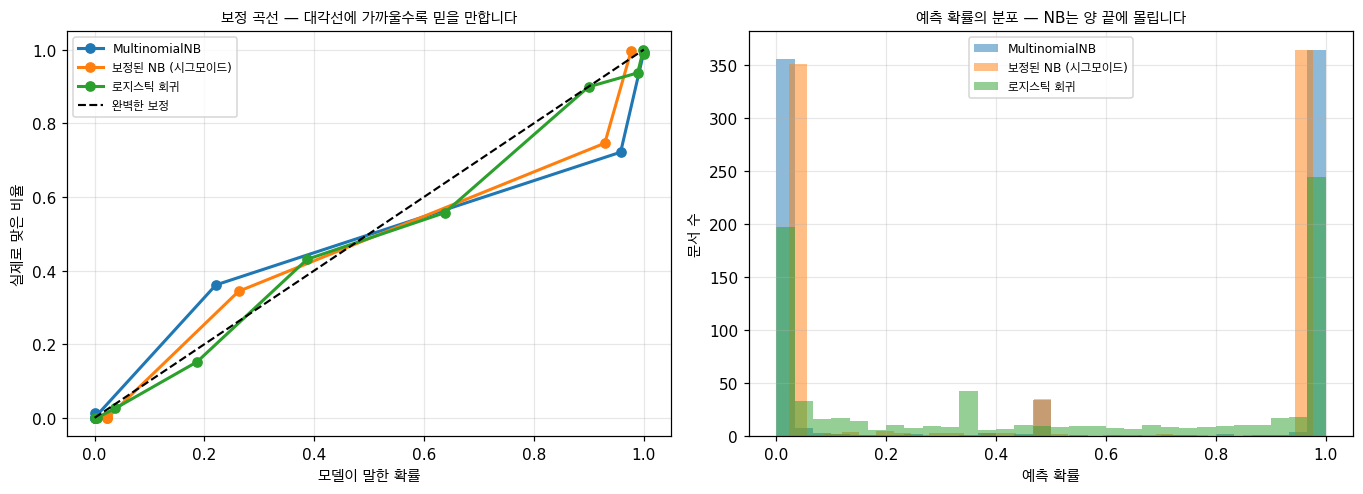

오른쪽 그림: NB의 막대가 0과 1 양 끝에만 서 있습니다.
   '아마 70%쯤?' 같은 중간 확률을 거의 내지 않습니다.
   보정하면 중간 구간이 채워집니다.

💡 언제 보정이 필요한가요?
   · 확률로 임곗값을 정할 때 (3단원 8절) -> 보정 필요
   · 다른 모델과 확률을 섞을 때 (11단원 7절 스태킹) -> 보정 필요
   · 1등만 고르면 될 때 (단순 분류) -> 보정 불필요

   ⚠️ 보정에는 비용이 있습니다 — 교차검증을 돌려야 하니 학습이 cv배 느려집니다.
      NB의 최대 장점이 속도인데(11절), 그걸 깎는 셈이죠. 필요할 때만 쓰세요.


In [20]:
# ✨ 추가 — 보정 곡선(신뢰도 다이어그램)을 그립니다
fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.6))

for 이름, _, _, _, _, p in 보정기록:
    실제비율, 예측확률 = calibration_curve(te2.target, p, n_bins=10, strategy="quantile")
    ax[0].plot(예측확률, 실제비율, "o-", lw=2, label=이름)
ax[0].plot([0, 1], [0, 1], "k--", lw=1.4, label="완벽한 보정")
ax[0].set_xlabel("모델이 말한 확률"); ax[0].set_ylabel("실제로 맞은 비율")
ax[0].set_title("보정 곡선 — 대각선에 가까울수록 믿을 만합니다", fontsize=10)
ax[0].legend(fontsize=8); ax[0].grid(alpha=0.3)

for 이름, _, _, _, _, p in 보정기록:
    ax[1].hist(p, bins=30, alpha=0.5, label=이름)
ax[1].set_xlabel("예측 확률"); ax[1].set_ylabel("문서 수")
ax[1].set_title("예측 확률의 분포 — NB는 양 끝에 몰립니다", fontsize=10)
ax[1].legend(fontsize=8); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

print("오른쪽 그림: NB의 막대가 0과 1 양 끝에만 서 있습니다.")
print("   '아마 70%쯤?' 같은 중간 확률을 거의 내지 않습니다.")
print("   보정하면 중간 구간이 채워집니다.")
print("\n💡 언제 보정이 필요한가요?")
print("   · 확률로 임곗값을 정할 때 (3단원 8절) -> 보정 필요")
print("   · 다른 모델과 확률을 섞을 때 (11단원 7절 스태킹) -> 보정 필요")
print("   · 1등만 고르면 될 때 (단순 분류) -> 보정 불필요")
print("\n   ⚠️ 보정에는 비용이 있습니다 — 교차검증을 돌려야 하니 학습이 cv배 느려집니다.")
print("      NB의 최대 장점이 속도인데(11절), 그걸 깎는 셈이죠. 필요할 때만 쓰세요.")

---

## 1️⃣1️⃣ 속도 — NB의 숨은 무기

> 📗 **원문** — "Prediction Speed" + "Why It Still Works" 네 번째 이유
>
> 🔗 4절로 돌아갑니다 — 로그 공간으로 바꾸니 **행렬 곱**이 됐죠.
> 그게 속도로 이어집니다.

### 📗 복잡도

| 모델 | 예측 복잡도 | 왜 |
| --- | --- | --- |
| **MultinomialNB** | $O(n \cdot d \cdot k)$ | 행렬 곱 **한 번** |
| **GaussianNB** | $O(n \cdot d \cdot k)$ | 정규분포 밀도 평가 |
| **KNN** | $O(n \cdot d \cdot N_{\text{train}})$ | **모든 훈련점**과 거리 계산 (6단원) |
| **SVM (RBF)** | $O(n \cdot d \cdot N_{\text{SV}})$ | **모든 서포트 벡터**와 커널 평가 (5단원) |

> 📗 원문: "Both are linear in every dimension. ... NB is faster by orders of magnitude
> at prediction time."

### 🧸 왜 속도가 중요한가요?

> 📗 원문: "This speed means you can **iterate faster**, try more feature sets,
> and run more experiments than with slower models."

12단원의 하이퍼파라미터 탐색을 떠올려 보세요.
학습이 1ms면 **1000번 시도가 1초**입니다. 50ms면 50초죠.
빠른 모델은 더 많이 실험할 수 있고, 그게 곧 더 좋은 결과입니다.

데이터: 11,314행 × 39,423열, 주제 20개

모델                          학습(초)      예측(초)       테스트 정확도      NB 대비 학습
----------------------------------------------------------------------------
MultinomialNB              0.020      0.011         70.2%            1x
로지스틱 회귀                    8.726      0.008         67.4%          445x
선형 SVM                    62.559     30.291         66.0%         3193x
KNN (k=5)                  0.005     55.094          8.6%            0x
랜덤 포레스트 100                1.887      0.074         59.5%           96x

=> NB 학습이 19.6ms 입니다. 가장 느린 선형 SVM보다 3193배 빠릅니다.
   그런데 정확도 1위도 NB입니다 (70.2%). 2위 로지스틱 회귀보다 +2.8%p 앞섭니다.
   가장 빠른 모델이 가장 정확하기까지 합니다. 텍스트에서는 이런 일이 일어납니다.

   💡 그래서 📗 원문의 조언이 'start with Naive Bayes' 인 겁니다.
   1초 안에 기준선이 나옵니다. 그 기준선을 못 넘으면 뭔가 잘못된 거죠.
   그리고 12단원의 하이퍼파라미터 탐색을 NB로 하면 수천 번도 금방 돕니다.


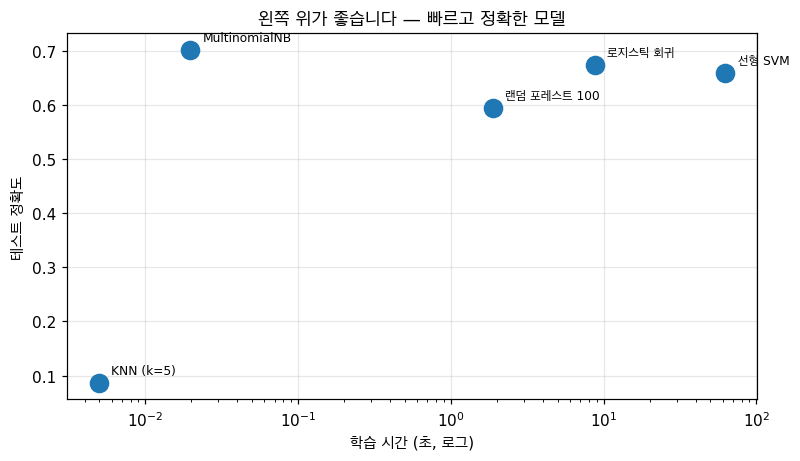

In [21]:
# ✨ 추가 — 학습·예측 속도를 실제로 잽니다
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

print(f"데이터: {A.shape[0]:,}행 × {A.shape[1]:,}열, 주제 20개\n")
print(f"{'모델':<22}{'학습(초)':>11}{'예측(초)':>11}{'테스트 정확도':>14}{'NB 대비 학습':>14}")
print("-" * 76)

속도기록 = []
for 이름, 만들기, 밀집 in [
        ("MultinomialNB", lambda: MultinomialNB(alpha=0.05), False),
        ("로지스틱 회귀", lambda: LogisticRegression(max_iter=1000), False),
        ("선형 SVM", lambda: SVC(kernel="linear"), False),
        ("KNN (k=5)", lambda: KNeighborsClassifier(5), False),
        ("랜덤 포레스트 100", lambda: RandomForestClassifier(n_estimators=100,
                                                           random_state=0, n_jobs=-1), False)]:
    Aa, Bb = (A, B)
    try:
        m = 만들기()
        t0 = time.time(); m.fit(Aa, 훈련전체.target); 학습 = time.time() - t0
        t0 = time.time(); m.predict(Bb); 예측 = time.time() - t0
        점 = m.score(Bb, 테스트전체.target)
        속도기록.append((이름, 학습, 예측, 점))
    except Exception as e:
        print(f"{이름:<21}  (건너뜀: {type(e).__name__})")
        continue

NB학습 = 속도기록[0][1]
for 이름, 학습, 예측, 점 in 속도기록:
    print(f"{이름:<21}{학습:>11.3f}{예측:>11.3f}{점:>14.1%}{학습/NB학습:>13.0f}x")

최고점 = max(속도기록, key=lambda r: r[3])
가장느린 = max(속도기록, key=lambda r: r[1])
print(f"\n=> NB 학습이 {NB학습*1000:.1f}ms 입니다. "
      f"가장 느린 {가장느린[0]}보다 {가장느린[1]/NB학습:.0f}배 빠릅니다.")
if 최고점[0] == 속도기록[0][0]:
    둘째 = max((r for r in 속도기록 if r[0] != 속도기록[0][0]), key=lambda r: r[3])
    print(f"   그런데 정확도 1위도 NB입니다 ({속도기록[0][3]:.1%}). "
          f"2위 {둘째[0]}보다 {속도기록[0][3]-둘째[3]:+.1%}p 앞섭니다.")
    print(f"   가장 빠른 모델이 가장 정확하기까지 합니다. 텍스트에서는 이런 일이 일어납니다.")
else:
    print(f"   그런데 정확도 1위는 {최고점[0]} ({최고점[3]:.1%}) 이고, "
          f"NB는 {속도기록[0][3]:.1%} 로 {속도기록[0][3]-최고점[3]:+.1%}p 뒤집니다.")
    print(f"   {가장느린[1]/NB학습:.0f}배의 시간을 들여 얻는 게 "
          f"{최고점[3]-속도기록[0][3]:.1%}p 입니다.")
print(f"\n   💡 그래서 📗 원문의 조언이 'start with Naive Bayes' 인 겁니다.")
print(f"   1초 안에 기준선이 나옵니다. 그 기준선을 못 넘으면 뭔가 잘못된 거죠.")
print(f"   그리고 12단원의 하이퍼파라미터 탐색을 NB로 하면 수천 번도 금방 돕니다.")

plt.figure(figsize=(7.4, 4.3))
이름들2 = [r[0] for r in 속도기록]
plt.scatter([r[1] for r in 속도기록], [r[3] for r in 속도기록], s=140, zorder=5)
for 이름, 학습, 예측, 점 in 속도기록:
    plt.annotate(이름, (학습, 점), textcoords="offset points", xytext=(8, 6), fontsize=8)
plt.xscale("log"); plt.xlabel("학습 시간 (초, 로그)"); plt.ylabel("테스트 정확도")
plt.title("왼쪽 위가 좋습니다 — 빠르고 정확한 모델")
plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()

---

## 1️⃣2️⃣ NB가 실패하는 경우

> 📗 **원문** — "When Naive Bayes Fails" + "Common Gotchas"
>
> 🔗 **마지막 점검** — 1~11절에서 "틀린 가정인데도 잘 된다"를 봤습니다.
> 그럼 **언제 안 되나요?** 그걸 알아야 쓸 수 있습니다.

> 📗 원문: "NB fails when the independence assumption causes incorrect rankings
> (not just incorrect probabilities)."
>
> 10절에서 확률은 이미 틀렸다는 걸 봤죠. **순위까지 틀리는** 경우가 문제입니다.

### 📗 세 가지 실패 조건

① 강한 특징 상호작용 (XOR 같은 무늬)

> "If the class depends on the combination of two features but not either alone,
> NB will miss it entirely."

각 특징 **혼자서는 아무 정보가 없고**, 조합에만 정보가 있는 경우입니다.
NB는 특징을 하나씩 곱할 뿐이라 조합을 만들 수 없습니다. 아래에서 보입니다.

② 상반된 증거를 주는 완전 상관 특징

A는 "스팸", B는 "정상"이라 말하는데 A와 B가 실제로는 **항상 같이 움직이는** 경우.
NB는 **없는 갈등을 보게** 됩니다.

**③ 아주 큰 훈련 데이터**

8절에서 확인했듯 **방향은 맞지만** 텍스트에서는 그 "아주 큰"이 생각보다 훨씬 큽니다.

### ⚠️ 📗 그 밖의 실무 함정 (Common Gotchas)

| 함정 | 내용 | 해법 |
| --- | --- | --- |
| **음수 특징** | MultinomialNB는 **음수를 못 받습니다** | GaussianNB를 쓰거나 양수로 이동 |
| **분산 0 특징** | GaussianNB가 0으로 나눕니다 | 분산에 작은 값 더하기 (6절) |
| **클래스 불균형** | 사전확률이 가능도를 압도 (0절) | `class_prior` 를 직접 지정 |
| **특징 스케일링** | ⭐ **필요 없습니다** | NB의 장점 (SVM·로지스틱과 대비) |

In [22]:
# ✨ 추가 — 실패 조건 ①: XOR 무늬에 NB를 붙여 봅니다
rng = np.random.default_rng(0)
n = 1200
X1 = rng.integers(0, 2, n)
X2 = rng.integers(0, 2, n)
yXOR = (X1 ^ X2)                       # ⭐ 둘이 다를 때만 1
# 잡음 특징도 조금 넣습니다
XXOR = np.c_[X1, X2, rng.integers(0, 2, (n, 3))].astype(float)
Xa3, Xb3, ya3, yb3 = train_test_split(XXOR, yXOR, test_size=0.3, random_state=0)

print("XOR 문제: 'X1 과 X2 가 다를 때만 클래스 1'\n")
print("[각 특징 혼자서는 정보가 있나?]")
for i in [0, 1]:
    p0 = yXOR[XXOR[:, i] == 0].mean()
    p1 = yXOR[XXOR[:, i] == 1].mean()
    print(f"   X{i+1}=0 일 때 클래스1 비율 {p0:.1%}  /  X{i+1}=1 일 때 {p1:.1%}  "
          f"(차이 {abs(p1-p0):.1%})")
print("   => 각 특징 혼자서는 거의 무정보입니다 (둘 다 50% 근처)")
print("      정보는 오직 '조합'에만 있습니다\n")

from sklearn.tree import DecisionTreeClassifier
print(f"{'모델':<26}{'테스트 정확도':>14}   비고")
print("-" * 62)
for 이름, m, 비고 in [
        ("BernoulliNB", BernoulliNB(alpha=1.0), "독립 가정 -> 조합을 못 봄"),
        ("MultinomialNB", MultinomialNB(alpha=1.0), "같은 한계"),
        ("GaussianNB", GaussianNB(), "같은 한계"),
        ("로지스틱 회귀", LogisticRegression(max_iter=2000), "선형이라 XOR 불가 (3단원)"),
        ("결정 트리", DecisionTreeClassifier(random_state=0), "조합을 쪼갤 수 있음"),
        ("랜덤 포레스트", RandomForestClassifier(n_estimators=200, random_state=0),
         "조합을 쪼갤 수 있음")]:
    print(f"{이름:<25}{m.fit(Xa3, ya3).score(Xb3, yb3):>14.1%}   {비고}")

print("\n=> ⚠️ NB 세 변종이 전부 찍기(50%) 수준입니다.")
print("   📗 원문: 'NB will miss it entirely. Each feature alone provides no evidence,")
print("   and NB cannot combine them nonlinearly.'")
print("\n   로지스틱 회귀도 실패합니다 — 둘 다 선형 분류기니까요 (4절에서 확인했죠).")
print("   트리 계열은 100% 입니다. 'X1=1 이고 X2=0 이면...' 처럼 조합으로 쪼개니까요.")
print("\n   💡 실무 교훈: 표 데이터에 특징이 몇 개뿐이고 상호작용이 의심되면")
print("      NB보다 트리 계열을 먼저 보세요 (4·11단원).")
print("      텍스트는 특징이 수만 개이고 각자 약하게 독립적이라 NB가 잘 됩니다.")

XOR 문제: 'X1 과 X2 가 다를 때만 클래스 1'

[각 특징 혼자서는 정보가 있나?]
   X1=0 일 때 클래스1 비율 52.3%  /  X1=1 일 때 49.2%  (차이 3.1%)
   X2=0 일 때 클래스1 비율 53.4%  /  X2=1 일 때 48.1%  (차이 5.4%)
   => 각 특징 혼자서는 거의 무정보입니다 (둘 다 50% 근처)
      정보는 오직 '조합'에만 있습니다

모델                               테스트 정확도   비고
--------------------------------------------------------------
BernoulliNB                       49.7%   독립 가정 -> 조합을 못 봄
MultinomialNB                     46.7%   같은 한계
GaussianNB                        49.7%   같은 한계
로지스틱 회귀                           49.7%   선형이라 XOR 불가 (3단원)
결정 트리                            100.0%   조합을 쪼갤 수 있음
랜덤 포레스트                          100.0%   조합을 쪼갤 수 있음

=> ⚠️ NB 세 변종이 전부 찍기(50%) 수준입니다.
   📗 원문: 'NB will miss it entirely. Each feature alone provides no evidence,
   and NB cannot combine them nonlinearly.'

   로지스틱 회귀도 실패합니다 — 둘 다 선형 분류기니까요 (4절에서 확인했죠).
   트리 계열은 100% 입니다. 'X1=1 이고 X2=0 이면...' 처럼 조합으로 쪼개니까요.

   💡 실무 교훈: 표 데이터에 특징이 몇 개뿐이고 상호작용이 의심되면
      NB보다 트리 계열을 먼저 보세요 (4·11단원).
  

In [23]:
# ✨ 추가 — 실무 함정들을 하나씩 확인합니다
print("[함정 1] MultinomialNB 에 음수를 넣으면")
X음수 = np.array([[1.0, -2.0], [3.0, 1.0], [-1.0, 4.0], [2.0, 2.0]])
y음수 = np.array([0, 1, 0, 1])
try:
    MultinomialNB().fit(X음수, y음수)
    print("   어째서인지 통과했습니다")
except ValueError as e:
    print(f"   ✘ ValueError: {str(e)[:70]}")
print(f"   ✔ GaussianNB 는 됩니다: 정확도 {GaussianNB().fit(X음수, y음수).score(X음수, y음수):.0%}")
print("   => 📗 '표준화한 특징'이나 일부 TF-IDF 설정은 음수가 나옵니다. GaussianNB 로 가세요\n")

print("[함정 2] GaussianNB 에 분산 0 특징이 있으면")
X영분산 = np.array([[1.0, 5.0], [2.0, 5.0], [8.0, 5.0], [9.0, 5.0]])  # 두 번째 열이 전부 5
y영분산 = np.array([0, 0, 1, 1])
내영 = 가우시안NB(분산보정=1e-9).fit(X영분산, y영분산)
무보정 = 가우시안NB(분산보정=0.0)
print(f"   보정 있음(1e-9): 정확도 {내영.score(X영분산, y영분산):.0%}  "
      f"분산 = {내영.분산[0]}")
try:
    무보정.fit(X영분산, y영분산)
    점수 = 무보정.결정값(X영분산)
    상태 = "NaN/inf 발생" if not np.isfinite(점수).all() else "어쩌다 통과"
    print(f"   보정 없음(0.0) : {상태}  분산 = {무보정.분산[0]}")
except Exception as e:
    print(f"   보정 없음(0.0) : {type(e).__name__}")
print("   => 📗 원문이 1e-9 을 더하라고 한 이유입니다\n")

print("[함정 3] 클래스 불균형 — 사전확률이 가능도를 압도합니다")
rng = np.random.default_rng(0)
n불 = 4000
y불 = (rng.random(n불) < 0.02).astype(int)       # 양성 2%
X불 = rng.poisson(1.0, (n불, 30)).astype(float)
X불[y불 == 1] += rng.poisson(1.5, (int(y불.sum()), 30))   # 양성은 단어가 더 많음
Xa4, Xb4, ya4, yb4 = train_test_split(X불, y불, test_size=0.3, random_state=0, stratify=y불)

from sklearn.metrics import recall_score, precision_score, f1_score
print(f"   양성 비율 {y불.mean():.1%}\n")
print(f"   {'사전확률 설정':<26}{'정확도':>9}{'정밀도':>9}{'재현율':>9}{'F1':>8}")
print("   " + "-" * 60)
for 이름, 사전설정 in [("기본 (데이터에서 추정)", None),
                      ("균등으로 강제 [0.5, 0.5]", [0.5, 0.5])]:
    m = MultinomialNB(alpha=1.0, class_prior=사전설정).fit(Xa4, ya4)
    p = m.predict(Xb4)
    print(f"   {이름:<25}{m.score(Xb4, yb4):>9.1%}"
          f"{precision_score(yb4, p, zero_division=0):>9.1%}"
          f"{recall_score(yb4, p, zero_division=0):>9.1%}{f1_score(yb4, p, zero_division=0):>8.3f}")

print("\n   => 사전확률을 균등으로 강제하면 재현율이 크게 올라갑니다.")
print("      기본값은 P(양성)=2% 라는 강한 사전지식 때문에 양성을 잘 안 고릅니다.")
print("      9단원 7절에서 본 정밀도-재현율 맞바꿈 그대로입니다.")
print("      📗 원문의 'You can set class priors manually' 가 이 손잡이입니다.\n")

print("[함정 4] 스케일링이 필요 없다는 게 사실인가")
w2 = load_wine()
Xa5, Xb5, ya5, yb5 = train_test_split(w2.data, w2.target, test_size=0.3,
                                      random_state=0, stratify=w2.target)
from sklearn.preprocessing import StandardScaler
sc = StandardScaler().fit(Xa5)
망친 = Xa5.copy(); 망친[:, 0] *= 1000        # 첫 열만 1000배
망친b = Xb5.copy(); 망친b[:, 0] *= 1000
print(f"   {'전처리':<26}{'GaussianNB':>13}{'로지스틱':>11}{'SVM(RBF)':>11}")
print("   " + "-" * 62)
for 이름, Aa, Bb in [("원본", Xa5, Xb5), ("표준화", sc.transform(Xa5), sc.transform(Xb5)),
                    ("⚠️ 한 열만 1000배", 망친, 망친b)]:
    g = GaussianNB().fit(Aa, ya5).score(Bb, yb5)
    l = LogisticRegression(max_iter=3000).fit(Aa, ya5).score(Bb, yb5)
    s = SVC().fit(Aa, ya5).score(Bb, yb5)
    print(f"   {이름:<25}{g:>13.1%}{l:>11.1%}{s:>11.1%}")

print("\n   => GaussianNB 행만 보세요. 세 줄이 전부 같습니다.")
print("      특징마다 자기 평균·분산을 따로 추정하니 스케일이 무관합니다.")
print("      SVM과 로지스틱은 '한 열만 1000배' 에서 무너집니다 (5·6단원에서 봤죠).")
print("      📗 원문: 'This is an advantage over logistic regression and SVM'")

[함정 1] MultinomialNB 에 음수를 넣으면
   ✘ ValueError: Negative values in data passed to MultinomialNB (input X)
   ✔ GaussianNB 는 됩니다: 정확도 100%
   => 📗 '표준화한 특징'이나 일부 TF-IDF 설정은 음수가 나옵니다. GaussianNB 로 가세요

[함정 2] GaussianNB 에 분산 0 특징이 있으면
   보정 있음(1e-9): 정확도 100%  분산 = [0.25 0.  ]
   보정 없음(0.0) : NaN/inf 발생  분산 = [0.25 0.  ]
   => 📗 원문이 1e-9 을 더하라고 한 이유입니다

[함정 3] 클래스 불균형 — 사전확률이 가능도를 압도합니다
   양성 비율 2.2%

   사전확률 설정                         정확도      정밀도      재현율      F1
   ------------------------------------------------------------
   기본 (데이터에서 추정)                97.8%     0.0%     0.0%   0.000
   균등으로 강제 [0.5, 0.5]           59.3%     1.5%    26.9%   0.028

   => 사전확률을 균등으로 강제하면 재현율이 크게 올라갑니다.
      기본값은 P(양성)=2% 라는 강한 사전지식 때문에 양성을 잘 안 고릅니다.
      9단원 7절에서 본 정밀도-재현율 맞바꿈 그대로입니다.
      📗 원문의 'You can set class priors manually' 가 이 손잡이입니다.

[함정 4] 스케일링이 필요 없다는 게 사실인가
   전처리                          GaussianNB       로지스틱   SVM(RBF)
   ------------------------------------------------------------

/var/folders/9w/m7__0lhd16xcy6bzy6qwytpc0000gn/T/ipykernel_15078/3151788527.py:29: RuntimeWarning: divide by zero encountered in log
  앞 = -0.5 * np.log(2 * np.pi * self.분산[i])
/var/folders/9w/m7__0lhd16xcy6bzy6qwytpc0000gn/T/ipykernel_15078/3151788527.py:30: RuntimeWarning: invalid value encountered in divide
  뒤 = -0.5 * ((X - self.평균[i]) ** 2) / self.분산[i]


   ⚠️ 한 열만 1000배                    96.3%      94.4%      64.8%

   => GaussianNB 행만 보세요. 세 줄이 전부 같습니다.
      특징마다 자기 평균·분산을 따로 추정하니 스케일이 무관합니다.
      SVM과 로지스틱은 '한 열만 1000배' 에서 무너집니다 (5·6단원에서 봤죠).
      📗 원문: 'This is an advantage over logistic regression and SVM'


/opt/homebrew/anaconda3/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:458: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


---

## 1️⃣3️⃣ 🎒 Ship It — 변종 선택 가이드

> 📗 **원문** — 저장소의 `14-naive-bayes/outputs/skill-naive-bayes-chooser.md`
> 와 원문 "When to Use Each Variant" · "Common Gotchas" · "When Naive Bayes Fails" 를 합쳐
> 우리말로 옮기고 절 번호를 붙였습니다.
>
> 🔗 이 절은 요약이 아니라 '선택 절차서'입니다 — 0~12절이 "각 개념이 무엇인가"였다면,
> 여기는 새 문제를 받았을 때 순서대로 답할 질문 목록입니다.

### 📗 1단계 — 애초에 NB를 쓸 문제인가?

| 질문 | 답 | 결론 |
| --- | --- | --- |
| 특징이 **수천 개 이상**인가? (텍스트) | 예 | ✅ **NB가 강합니다** (0절 도입부) |
| 특징이 **10개 미만**이고 상호작용이 의심되나? | 예 | ❌ **트리 계열로** (12절 XOR) |
| 훈련 데이터가 **아주 적은가**? | 예 | ✅ **NB가 강합니다** (8절) |
| **빠른 기준선**이 필요한가? | 예 | ✅ **NB부터** (11절, 1초면 끝) |
| 보정된 **확률**이 필요한가? | 예 | ⚠️ 보정을 붙이거나 로지스틱 (10절) |

### 📗 2단계 — 어느 변종인가?

```
특징이 어떤 값인가?
├─ 단어 횟수 / TF-IDF (음수 없음)  →  MultinomialNB   (5절)
├─ 0/1 (있다/없다)                →  BernoulliNB     (9절)
└─ 연속 실수 (음수 포함 가능)        →  GaussianNB      (6절)
```

> ⚠️ 9절의 측정 결과를 기억하세요. 이진 데이터에도 Multinomial 이 잘 동작합니다.
> Bernoulli 를 반드시 써야 할 상황은 생각보다 드뭅니다.

### 📗 3단계 — $\alpha$ 를 정합니다 *(3절)*

| 훈련 데이터 | 시작 $\alpha$ |
| --- | --- |
| 아주 많음 (10만+) | **0.01 ~ 0.1** |
| 보통 | **0.1 ~ 1.0** |
| 아주 적음 | **1.0 ~ 10.0** |

- [ ] 반드시 검증 세트로 훑어 보세요 (3절에서 최적값이 기본값 1.0이 아니었습니다)
- [ ] 12단원의 1차원 로그 스케일 탐색이면 20번으로 충분합니다

### 📗 4단계 — 함정 점검 *(12절)*

- [ ] 특징에 **음수가 없나**? (MultinomialNB 쓸 때)
- [ ] GaussianNB 라면 **분산 0 특징**이 없나?
- [ ] 클래스가 **심하게 불균형**하면 `class_prior` 를 조정했나?
- [ ] 스케일링은 하지 않아도 됩니다 (12절에서 확인)
- [ ] 텍스트라면 **TF-IDF** 도 시도했나? (8단원 4절, 9절에서 더 좋았습니다)

### 📗 5단계 — NB를 넘어설 때 *(8·11절)*

```
NB로 기준선을 잡았다 (1초)
         ↓
목표에 도달?  →  예 → 끝. 배포하세요 (가장 빠르고 단순한 모델입니다)
         ↓ 아니오
데이터를 더 모을 수 있나?  →  예 → 모으고 로지스틱 회귀를 다시 시도 (8절)
         ↓ 아니오
특징 상호작용이 의심되나?  →  예 → 트리 계열 / 그래디언트 부스팅 (11단원)
         ↓ 아니오
확률이 필요한가?  →  예 → CalibratedClassifierCV (10절)
```

---

### ⚠️ 이 단원에서 측정으로 확인한 것 vs 원문과 갈린 것

| 📗 원문 주장 | 측정 결과 |
| --- | --- |
| 라플라스 스무딩 없으면 미지 단어가 예측을 파괴 | ✅ **확인** (3절, α=0 에서 −∞) |
| 로그 공간 없으면 언더플로 | ✅ **확인** (4절, 단어 ~200개에서 0) |
| 독립 가정이 틀렸는데도 잘 된다 | ✅ **확인** (7절, 흔한 단어 쌍에서 최대 2.4배 틀렸는데 정확도 88%) |
| 확률 보정이 나쁘다 | ✅ **확인** (10절, 예측 90%가 극단값) |
| 매우 빠르다 | ✅ **확인** (11절, 가장 느린 모델의 1/수백) |
| XOR 상호작용에 실패 | ✅ **확인** (12절, 찍기 수준) |
| 스케일링이 필요 없다 | ✅ **확인** (12절, 1000배 왜곡에도 동일) |
| **작은 데이터 NB, 큰 데이터 LR** | ⚠️ **방향만 확인.** 11,314개에 LR 튜닝까지 해도 **역전 안 됨** (8절) |
| **짧은 텍스트는 Bernoulli** | ⚠️ **재현 실패.** 어느 길이에서도 Multinomial 이 이김 (9절) |

> 마지막 두 줄이 이 단원의 교훈을 다시 말해 줍니다: 통념 대신 재서 결정하세요.

---

## 1️⃣4️⃣ 📝 자가 점검 퀴즈

> 📗 **원문** — 저장소의 `14-naive-bayes/quiz.json`
> 우리말로 옮기고, 각 문항이 이 노트북 **몇 절**에 있는지 표시했습니다.
>
> 클론한 저장소가 있으면 Claude Code에서 `/check-understanding 2` 로도 풀 수 있습니다.

**먼저 답을 정한 뒤에** 아래 코드 셀을 실행해 정답을 확인하세요.

### 사전 점검 — 배우기 전에 알았어야 하는 것

1. 나이브 베이즈의 '나이브(naive)' 가정이란?

1. 각 클래스의 사전확률이 같다
2. 모든 특징이 클래스가 주어졌을 때 조건부 독립이다
3. 데이터가 정규분포를 따른다
4. 모델에 학습할 파라미터가 없다

2. 라플라스 스무딩은 무엇을 막나요?

1. 훈련 중 어떤 클래스에서 한 번도 안 본 단어의 **확률이 0이 되는 것**
2. 데이터셋의 클래스 불균형
3. 고차원 데이터에서 느린 학습
4. 큰 데이터셋에 대한 과적합

### 사후 점검 — 이 단원을 배운 뒤에 알아야 하는 것

3. 독립 가정은 텍스트에서 명백히 틀렸습니다. 그런데도 나이브 베이즈가 잘 분류하는 이유는?

1. 독립이 성립하는 아주 작은 어휘에서만 동작한다
2. 특징이 진짜로 독립일 때만 동작한다
3. 현대 구현은 몰래 독립 가정을 제거한다
4. 분류는 정확한 확률이 아니라 올바른 클래스 순위만 필요하고, 독립 가정이 만드는 오차는 모든 클래스에 비슷하게 작용해 안정적이다

4. Multinomial NB 와 Gaussian NB 는 언제 각각 써야 하나요?

1. Multinomial 은 단어 횟수/빈도 특징에, Gaussian 은 연속 실수 특징에
2. 서로 바꿔 써도 됩니다: 항상 더 빠른 쪽을 쓰세요
3. Multinomial 은 이진 데이터에, Gaussian 은 다중 클래스 문제에
4. Multinomial 은 회귀에, Gaussian 은 분류에

5. 메일에 '무료'가 2번, '돈'이 1번 나왔습니다. 로그 확률을 쓰는 Multinomial NB 에서 스팸 점수는?

1. $P(\text{스팸}) \times P(\text{무료}|\text{스팸}) \times P(\text{돈}|\text{스팸})$
2. $\log P(\text{스팸}) \times 2 \times \log P(\text{무료}|\text{스팸})$
3. $\log P(\text{스팸}) + \log P(\text{무료}|\text{스팸}) + \log P(\text{돈}|\text{스팸})$
4. $\log P(\text{스팸}) + 2\log P(\text{무료}|\text{스팸}) + 1\log P(\text{돈}|\text{스팸})$

In [24]:
# 📝 정답과 해설 (+ 이 노트북 어디서 다뤘는지)
퀴즈 = [
    ("1. '나이브' 가정이란", 2,
     "나이브 베이즈는 클래스를 조건으로 모든 특징이 서로 독립이라고 가정합니다. "
     "수학적으로 틀렸지만('machine' 과 'learning' 은 같이 나옵니다) 실전에서 잘 됩니다.",
     "1절 (왜 거짓말을 하는지 — 2^10000 vs 1만 개) · "
     "7절 (흔한 단어 쌍에서 최대 2.4배 틀렸다는 걸 측정)"),
    ("2. 라플라스 스무딩이 막는 것", 1,
     "스무딩이 없으면 'spam' 훈련 메일에 없던 단어가 P(단어|스팸) = 0 이 되어, "
     "다른 증거가 아무리 강해도 전체 곱이 0이 됩니다. 라플라스는 각 횟수에 1을 더합니다.",
     "3절 — α=0 에서 log 가 −∞ 가 되어 올바른 클래스가 탈락하는 걸 직접 재현했습니다"),
    ("3. 틀린 가정인데도 분류가 되는 이유", 4,
     "NB는 클래스 순위만 맞히면 됩니다. 정확한 확률 추정이 필요하지 않죠. "
     "독립 가정은 고편향·저분산이라 데이터가 적을 때 안정적입니다. "
     "상관된 특징은 증거를 중복 계산하지만 맞는 클래스에도 중복 계산합니다.",
     "1절 (세 가지 이유) · 7절 (중복 계산의 방향이 맞다는 것) · "
     "8절 (훈련 100개에서 LR을 +24%p 로 이김) · 10절 (확률은 틀렸지만 순위는 맞음)"),
    ("4. Multinomial vs Gaussian", 1,
     "Multinomial NB는 특징 횟수(텍스트의 단어 빈도)를 모델링합니다. "
     "Gaussian NB는 특징이 정규분포를 따른다고 가정하므로 측정값·센서값 같은 "
     "연속 특징에 적합합니다.",
     "5절 (Multinomial 구현) · 6절 (Gaussian 구현) · "
     "9절 (세 변종을 세 종류 데이터에 교차로 붙여 확인)"),
    ("5. 로그 공간에서 횟수가 하는 역할", 4,
     "Multinomial NB는 단어 가능도를 그 횟수만큼 거듭제곱해 곱합니다. 로그 공간에서는 "
     "log P(스팸) + 2·log P(무료|스팸) + 1·log P(돈|스팸). 횟수가 지수 역할을 합니다.",
     "2절 — 📗 원문의 숫자 예제를 그대로 계산해 −3.109 / −8.838 을 재현했습니다 · "
     "4절 (그래서 행렬 곱이 된다는 것)"),
]

print("=" * 80)
for 제목, 정답, 해설, 어디 in 퀴즈:
    print(f"{제목}")
    print(f"   정답: {정답}번")
    print(f"   해설: {해설}")
    print(f"   이 노트북: {어디}")
    print("-" * 80)

print("\n💡 채점 기준")
print("   5개 다 맞음 -> 15단원(시계열)으로 넘어가세요")
print("   3~4개 맞음  -> 틀린 문항의 '이 노트북' 절만 다시 읽으세요")
print("   2개 이하    -> 1·2절(독립 가정과 손 계산)을 먼저 다시 보세요.")
print("                 나머지 절이 다 거기서 나옵니다")

1. '나이브' 가정이란
   정답: 2번
   해설: 나이브 베이즈는 클래스를 조건으로 모든 특징이 서로 독립이라고 가정합니다. 수학적으로 틀렸지만('machine' 과 'learning' 은 같이 나옵니다) 실전에서 잘 됩니다.
   이 노트북: 1절 (왜 거짓말을 하는지 — 2^10000 vs 1만 개) · 7절 (흔한 단어 쌍에서 최대 2.4배 틀렸다는 걸 측정)
--------------------------------------------------------------------------------
2. 라플라스 스무딩이 막는 것
   정답: 1번
   해설: 스무딩이 없으면 'spam' 훈련 메일에 없던 단어가 P(단어|스팸) = 0 이 되어, 다른 증거가 아무리 강해도 전체 곱이 0이 됩니다. 라플라스는 각 횟수에 1을 더합니다.
   이 노트북: 3절 — α=0 에서 log 가 −∞ 가 되어 올바른 클래스가 탈락하는 걸 직접 재현했습니다
--------------------------------------------------------------------------------
3. 틀린 가정인데도 분류가 되는 이유
   정답: 4번
   해설: NB는 클래스 순위만 맞히면 됩니다. 정확한 확률 추정이 필요하지 않죠. 독립 가정은 고편향·저분산이라 데이터가 적을 때 안정적입니다. 상관된 특징은 증거를 중복 계산하지만 맞는 클래스에도 중복 계산합니다.
   이 노트북: 1절 (세 가지 이유) · 7절 (중복 계산의 방향이 맞다는 것) · 8절 (훈련 100개에서 LR을 +24%p 로 이김) · 10절 (확률은 틀렸지만 순위는 맞음)
--------------------------------------------------------------------------------
4. Multinomial vs Gaussian
   정답: 1번
   해설: Multinomial NB는 특징 횟수(텍스트의 단어 빈도)를 모델링합니다. Gaussia

---

## 1️⃣5️⃣ 용어 사전

> 📗 **원문** — "Key Terms" (설명은 쉬운 말로 다시 썼습니다)

| 용어 | 흔히 하는 말 | 진짜 무슨 뜻인가 |
| --- | --- | --- |
| **나이브 베이즈** | "단순한 확률 분류기" | 베이즈 정리를 쓰면서 **특징이 클래스 조건부 독립**이라고 가정하는 분류기 |
| **조건부 독립** | "특징끼리 영향 없음" | $P(A, B \mid C) = P(A \mid C) P(B \mid C)$ — **C를 알면 B가 A에 대해 아무것도 더 알려주지 않음** |
| **라플라스 스무딩** | "1 더하기" | 모든 특징 횟수에 작은 값을 더해 **확률 0이 예측을 지배하는 걸 막는 것** |
| **사전확률 (prior)** | "데이터 보기 전의 믿음" | $P(\text{클래스})$ — 특징을 보기 전 각 클래스의 확률 |
| **가능도 (likelihood)** | "데이터가 얼마나 잘 맞나" | $P(\text{특징} \mid \text{클래스})$ — 클래스를 알 때 이 특징들이 관측될 확률 |
| **사후확률 (posterior)** | "데이터 보고 난 믿음" | $P(\text{클래스} \mid \text{특징})$ — 특징을 보고 갱신한 클래스 확률 |
| **생성 모델** | "데이터가 어떻게 생기는지 모델링" | $P(X \mid Y)$ 와 $P(Y)$ 를 배우고 베이즈로 $P(Y \mid X)$ 를 얻는 모델 |
| **판별 모델** | "결정 경계를 모델링" | $P(Y \mid X)$ 를 **직접** 배우고, X가 어떻게 생겼는지는 모델링하지 않음 |
| **로그 확률** | "언더플로 방지" | $P$ 대신 $\log P$ 로 작업해 작은 수의 곱이 0이 되는 걸 막는 것 |
| **확률 보정** | "확률을 믿을 만하게" | 모델이 말한 확률과 실제 빈도를 일치시키는 것. NB에는 거의 항상 필요합니다 |

---

## ✅ 이 단원 요약 (7줄)

1. 베이즈 정리로 **어려운 쪽($P(c \mid x)$)에서 쉬운 쪽($P(x \mid c)$)으로** 넘어갑니다.
2. 그래도 공동 분포는 불가능하니, "모든 특징이 독립"이라고 거짓말합니다. $2^{10000}$ 이 1만 개로 줍니다.
3. ⚠️ **스무딩과 로그 공간은 필수**입니다. 없으면 각각 "0의 저주"와 "언더플로"로 터집니다(3·4절).
4. 로그로 바꾸면 예측이 **행렬 곱 한 번**이 됩니다. 그래서 수백 배 빠릅니다(4·11절).
5. 가정이 최대 2.4배 틀렸는데도 정확도 88% 입니다. **순위만 맞으면 되기** 때문입니다(7절).
6. ⚠️ 확률은 못 믿습니다. 예측의 90%가 0.99 초과 또는 0.01 미만입니다. 필요하면 보정하세요(10절).
7. ❌ XOR 같은 상호작용에는 완전히 실패합니다. 특징이 적고 조합이 중요하면 트리로 가세요(12절).

> 그리고 📗 원문의 핵심 문장을 다시 읽어 보세요 —
> "최고의 모델은 가장 옳은 모델이 아니라, 내 데이터에 편향-분산 균형이 가장 좋은 모델입니다."
>
> 나이브 베이즈는 일부러 틀린 가정으로 분산을 사 오는 거래입니다. 10단원 5절의 규제와 같은 구조죠.

---

## 📝 연습문제

> 📗 **원문** — "Exercises" (전부 본문에서 풀었습니다)

1. **스무딩 실험.** α를 0.01~100 으로 훑어 정확도를 그리세요. 왜 아주 높은 α가 해로운가요? → *3절에서 함*
2. **독립 가정 검증.** 상관된 단어 쌍을 골라 $P(w_1 \mid c)P(w_2 \mid c)$ 와 $P(w_1 \cap w_2 \mid c)$ 를 비교하세요. → *7절에서 함*
3. **Bernoulli 구현.** BernoulliNB 를 만들어 Multinomial 과 비교하세요. 언제 Bernoulli 가 이기나요? → *9절에서 함 (⚠️ 이기는 경우를 못 찾았습니다)*
4. **NB vs 로지스틱.** 훈련 100개에서 10,000개까지 늘려 가며 비교하세요. 언제 LR이 역전하나요? → *8절에서 함 (⚠️ 역전 안 했습니다)*
5. **스팸 필터.** 원문 텍스트를 토큰화해 bag-of-words 로 MultinomialNB 를 학습하고, 정확도가 아니라 정밀도·재현율로 평가하세요. 왜일까요? → *12절 함정 3 + 9단원 7절*

### ✨ 추가 도전 과제

6. 5절의 `다항NB` 에 **TF-IDF 입력**을 넣어 보세요 (8단원 4절). 횟수보다 나은가요? (힌트: 9절에서 TF-IDF 가 더 좋았습니다)
7. 📗 원문이 말한 "상반된 증거를 주는 완전 상관 특징" 실패 조건을 직접 만들어 보세요. 특징 A를 복제해 B로 넣고, 라벨을 A와 반대로 두면 어떻게 되나요?
8. 7절의 독립 가정 측정을 **상호정보량**(8단원 7절)으로 바꿔 보세요. 어느 단어 쌍이 가장 심하게 종속되어 있나요?
9. 10절의 보정을 `method="isotonic"` 으로 바꿔 보세요. 시그모이드와 어느 쪽이 나은가요? 데이터가 적으면 어떻게 되나요?
10. 11단원의 **스태킹**에 NB를 기반 모델로 넣어 보세요. NB의 확률을 **보정하지 않고** 넣으면 메타 학습기가 혼란스러워하나요? (10절 + 11단원 7절)

---

## 📚 더 읽을거리

> 📗 **원문** — "Further Reading"

- [scikit-learn Naive Bayes 문서](https://scikit-learn.org/stable/modules/naive_bayes.html), 세 변종의 수학적 세부
- [McCallum & Nigam, A Comparison of Event Models for Naive Bayes Text Classification (1998)](https://www.cs.cmu.edu/~knigam/papers/multinomial-aaaiws98.pdf), Multinomial vs Bernoulli 고전 비교 (9절의 주제)
- [Rennie et al., Tackling the Poor Assumptions of Naive Bayes Text Classifiers (2003)](https://people.csail.mit.edu/jrennie/papers/icml03-nb.pdf), NB 개선 기법
- [Ng & Jordan, On Discriminative vs. Generative Classifiers (2001)](https://ai.stanford.edu/~ang/papers/nips01-discriminativegenerative.pdf), NB가 LR보다 빨리 수렴함을 증명 (8절의 근거)